# E-commerce Sales Analytics: End-to-End Data Analysis Project

## Business problem
An online store wants to know **what sells, where, when, to whom, and at what cost**. This project analyses 5,000 orders to find the main revenue drivers, check whether discounts are worth it, understand customer behaviour, and support the findings with statistical tests.

## Questions answered
1. How healthy is the business? (revenue, orders, average order value, discounts, ratings)
2. Which **categories** and **regions** earn the most - and the least?
3. How does revenue change by **year, quarter, month and weekday**? Is there a real trend?
4. How do customers **pay**, and does payment method depend on what they buy?
5. How do **price levels and discounts** affect order value and revenue leakage?
6. Who are the best customers? (**RFM segmentation**, top customers, Pareto curve)
7. How satisfied are customers, and does **delivery time** or **discount** change satisfaction?
8. Which differences are **statistically significant** and which are just noise?

## Dataset
| Column | Meaning |
|---|---|
| `order_id`, `order_date`, `customer_id` | order identifier, date (month/day/year) and customer |
| `product_category`, `region` | Beauty / Clothing / Electronics / Home, and East / West / North / South |
| `quantity`, `unit_price`, `discount` | units bought, price per unit, discount (0.10 = 10%) |
| `payment_method` | Card / COD / Wallet |
| `delivery_days`, `customer_rating` | delivery time in days, rating from 1 to 5 |
| `revenue` | final amount = quantity x unit_price x (1 - discount) |

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, SciPy (statistical tests).

**Workflow:** load -> validate and clean -> KPIs -> exploratory analysis -> customer segmentation -> statistical tests -> insights and recommendations.

## 1. Setup

In [1]:
import warnings
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (9, 5), "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False,
})

NAVY, BLUE, LIGHT, GREY = "#1F3864", "#2E75B6", "#9DC3E6", "#A5A5A5"
GREEN, RED, ORANGE = "#2E7D32", "#C62828", "#ED7D31"
COLORS = [NAVY, BLUE, LIGHT, GREY]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
thousands = ticker.FuncFormatter(lambda x, _: f"{x:,.0f}")

DATA_PATH = "ecommerce_sales_analytics_50001.csv"     # keep the CSV in the same folder as this notebook
CHART_DIR = Path("charts")                            # every chart is also saved here as a PNG
CHART_DIR.mkdir(exist_ok=True)


def finish(name):
    """Tidy the layout, save the chart as PNG and show it."""
    plt.tight_layout()
    plt.savefig(CHART_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def highlight(series):
    """Green for the highest bar, red for the lowest, blue for the rest."""
    return [GREEN if v == series.max() else RED if v == series.min() else BLUE for v in series.values]


def bar_on(ax, series, title, xlabel, ylabel, colors=None, fmt="{:,.0f}", money=True):
    bars = ax.bar(series.index.astype(str), series.values, color=colors or BLUE)
    ax.bar_label(bars, labels=[fmt.format(v) for v in series.values], padding=3, fontsize=9)
    if money:
        ax.yaxis.set_major_formatter(thousands)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.margins(y=0.15); ax.grid(axis="x", visible=False)


def summarize(by):
    """Revenue, orders, units, average order value, rating and revenue share for any column."""
    out = (df.groupby(by, observed=True)
             .agg(revenue=("revenue", "sum"), orders=("order_id", "count"), units=("quantity", "sum"),
                  avg_order_value=("revenue", "mean"), avg_rating=("customer_rating", "mean"),
                  avg_delivery_days=("delivery_days", "mean")))
    out["revenue_share_%"] = out["revenue"] / out["revenue"].sum() * 100
    return out

## 2. Data overview
First look at the raw data: size, columns, data types, statistics and the categories present.

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head(10)

Rows: 5,000   Columns: 12


,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.70,"1,883.20"
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.90,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.50,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.60,"2,569.90"
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.90,468.56
5,10006,1/6/2022,1071,Electronics,West,2,264.44,0.20,Card,3,3.30,423.10
6,10007,1/7/2022,1700,Clothing,South,6,564.60,0.23,Card,1,1.80,"2,608.45"
7,10008,1/8/2022,1020,Beauty,North,6,265.71,0.13,Card,2,3.70,"1,387.01"
8,10009,1/9/2022,1614,Clothing,South,6,224.65,0.27,Card,2,1.40,983.97
9,10010,1/10/2022,1121,Clothing,West,4,272.71,0.06,Card,10,4.50,"1,025.39"


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   str    
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   str    
 4   region            5000 non-null   str    
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   str    
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), str(4)
memory usage: 468.9 KB


In [4]:
df.describe()

,order_id,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,"5,000.00","5,000.00","5,000.00","5,000.00","5,000.00","5,000.00","5,000.00","5,000.00"
mean,"12,500.50","1,505.70",4.04,308.42,0.18,6.12,2.97,"1,021.96"
std,"1,443.52",290.84,2.02,169.26,0.10,3.15,1.16,825.58
min,"10,001.00","1,000.00",1.00,15.15,0.00,1.00,1.00,11.21
25%,"11,250.75","1,253.00",2.00,161.90,0.09,3.00,2.00,354.53
50%,"12,500.50","1,510.00",4.00,309.89,0.18,6.00,3.00,796.65
75%,"13,750.25","1,761.00",6.00,455.56,0.27,9.00,4.00,"1,515.69"
max,"15,000.00","1,999.00",7.00,599.96,0.35,11.00,5.00,"4,119.33"


In [5]:
for col in ["product_category", "region", "payment_method"]:
    print(f"{col}: {df[col].nunique()} values -> {sorted(df[col].unique())}")
print(f"customer_id: {df['customer_id'].nunique():,} unique customers")

product_category: 4 values -> ['Beauty', 'Clothing', 'Electronics', 'Home']
region: 4 values -> ['East', 'North', 'South', 'West']
payment_method: 3 values -> ['COD', 'Card', 'Wallet']
customer_id: 989 unique customers


## 3. Data cleaning, validation and feature engineering
Convert `order_date` to a real date, then create the helper columns used in the analysis (time parts, gross sales, discount amount, price band, discount band, order size). Run validation checks before trusting any number.

In [6]:
# Dates in the file are month/day/year, e.g. 1/2/2022 = 2 January 2022
df["order_date"] = pd.to_datetime(df["order_date"], format="mixed")

df["order_year"] = df["order_date"].dt.year
df["quarter"] = df["order_date"].dt.quarter
df["order_month"] = df["order_date"].dt.month
df["weekday"] = df["order_date"].dt.dayofweek                    # 0 = Monday
df["gross_sales"] = df["quantity"] * df["unit_price"]           # before discount
df["discount_amount"] = df["gross_sales"] * df["discount"]       # money given away

df["price_band"] = pd.qcut(df["unit_price"], 4, labels=["Low", "Mid-low", "Mid-high", "High"])
df["discount_band"] = pd.cut(df["discount"], bins=[0, 0.10, 0.20, 0.30, 1.0],
                             labels=["0-9%", "10-19%", "20-29%", "30%+"], right=False, include_lowest=True)
df["order_size"] = pd.cut(df["quantity"], bins=[0, 2, 4, 6, np.inf], labels=["1-2", "3-4", "5-6", "7+"])

df[["order_date", "order_year", "quarter", "weekday", "gross_sales", "discount_amount",
    "price_band", "discount_band", "order_size"]].head()

,order_date,order_year,quarter,weekday,gross_sales,discount_amount,price_band,discount_band,order_size
0,2022-01-01,2022,1,5,"2,615.55",732.35,Mid-high,20-29%,7+
1,2022-01-02,2022,1,6,334.18,30.08,Low,0-9%,7+
2,2022-01-03,2022,1,0,933.84,289.49,Mid-high,30%+,3-4
3,2022-01-04,2022,1,1,"2,622.35",52.45,High,0-9%,5-6
4,2022-01-05,2022,1,2,699.35,230.79,Low,30%+,5-6


In [7]:
expected_revenue = (df["gross_sales"] - df["discount_amount"]).round(2)

checks = pd.DataFrame({
    "Check": ["Missing values", "Duplicate rows", "Duplicate order_id",
              "Revenue differs from qty x price x (1 - discount) by > 0.02",
              "Discount outside 0-100%", "Rating outside 1-5",
              "Quantity or unit price <= 0", "Delivery days <= 0"],
    "Issues found": [int(df.isna().sum().sum()), int(df.duplicated().sum()), int(df["order_id"].duplicated().sum()),
                     int(((expected_revenue - df["revenue"]).abs() > 0.02).sum()),
                     int(((df["discount"] < 0) | (df["discount"] > 1)).sum()),
                     int(((df["customer_rating"] < 1) | (df["customer_rating"] > 5)).sum()),
                     int(((df["quantity"] <= 0) | (df["unit_price"] <= 0)).sum()),
                     int((df["delivery_days"] <= 0).sum())],
})
checks["Status"] = np.where(checks["Issues found"] == 0, "PASS", "CHECK")
checks

,Check,Issues found,Status
0,Missing values,0,PASS
1,Duplicate rows,0,PASS
2,Duplicate order_id,0,PASS
3,Revenue differs from qty x price x (1 - discount) by > 0.02,0,PASS
4,Discount outside 0-100%,0,PASS
5,Rating outside 1-5,0,PASS
6,Quantity or unit price <= 0,0,PASS
7,Delivery days <= 0,0,PASS


In [8]:
first, last = df["order_date"].min(), df["order_date"].max()
future_orders = int((df["order_date"] > pd.Timestamp(date.today())).sum())
days_per_year = df.groupby("order_year")["order_date"].nunique()
PARTIAL_YEAR = int(days_per_year.index[-1]) if days_per_year.iloc[-1] < 365 else None

q1, q3 = df["revenue"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
n_outliers = int((df["revenue"] > upper_fence).sum())

print(f"Date range            : {first:%d %b %Y} to {last:%d %b %Y}  ({days_per_year.sum():,} order days)")
print(f"Orders dated after today ({date.today():%d %b %Y}): {future_orders:,}")
print(f"Partial year          : {PARTIAL_YEAR} ({days_per_year.iloc[-1]} days of data)")
print(f"High-revenue outliers : {n_outliers} orders above {upper_fence:,.0f} (IQR rule) - kept, they are valid big orders")

Date range            : 01 Jan 2022 to 09 Sep 2035  (5,000 order days)
Orders dated after today (20 Oct 2026): 3,246
Partial year          : 2035 (252 days of data)
High-revenue outliers : 67 orders above 3,257 (IQR rule) - kept, they are valid big orders


**Result:** the data is clean - no missing values, duplicates or invalid numbers, and `revenue` matches the formula on every row (differences are only 0.01 rounding).
**Watch-outs:** (1) order dates run into the future (up to 2035) and the last year is incomplete, so the data looks synthetic and the last year is treated as *partial*; (2) a few large orders are statistical outliers, but they are valid (high quantity x high price), so they are kept.

## 4. Executive summary: key performance indicators

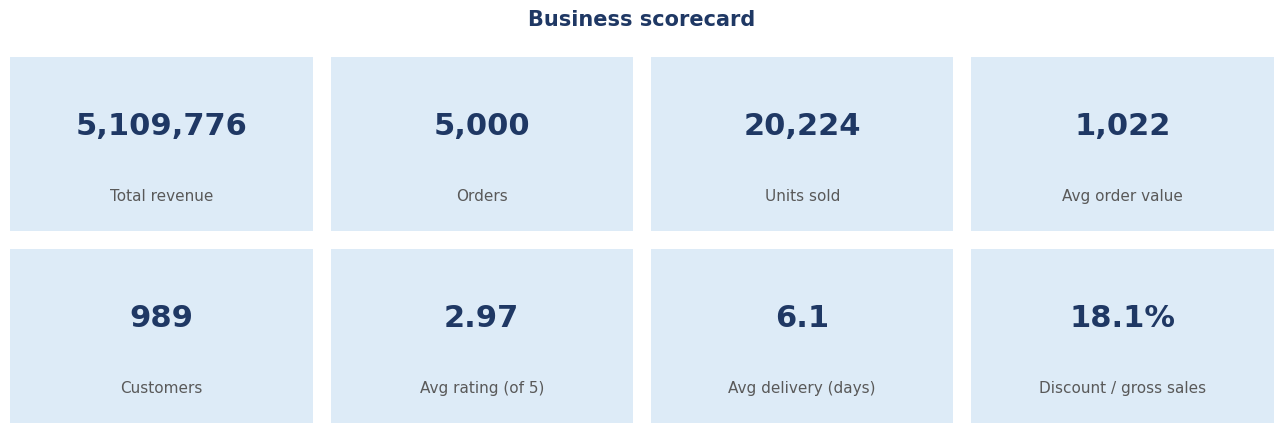

In [9]:
total_revenue = df["revenue"].sum()
total_orders = df["order_id"].nunique()
total_units = df["quantity"].sum()
aov = total_revenue / total_orders
gross_total = df["gross_sales"].sum()
discount_total = df["discount_amount"].sum()

tiles = [("Total revenue", f"{total_revenue:,.0f}"), ("Orders", f"{total_orders:,}"),
         ("Units sold", f"{total_units:,}"), ("Avg order value", f"{aov:,.0f}"),
         ("Customers", f"{df['customer_id'].nunique():,}"), ("Avg rating (of 5)", f"{df['customer_rating'].mean():.2f}"),
         ("Avg delivery (days)", f"{df['delivery_days'].mean():.1f}"), ("Discount / gross sales", f"{discount_total / gross_total:.1%}")]

fig, axes = plt.subplots(2, 4, figsize=(13, 4.4))
for ax, (label, value) in zip(axes.ravel(), tiles):
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color="#DDEBF7"))
    ax.text(0.5, 0.60, value, ha="center", va="center", fontsize=22, fontweight="bold", color=NAVY, transform=ax.transAxes)
    ax.text(0.5, 0.20, label, ha="center", va="center", fontsize=11, color="#595959", transform=ax.transAxes)
fig.suptitle("Business scorecard", fontsize=15, fontweight="bold", color=NAVY)
plt.subplots_adjust(wspace=0.06, hspace=0.12)
finish("01_kpi_scorecard")

In [10]:
kpi_table = pd.DataFrame(tiles + [("Gross sales (before discount)", f"{gross_total:,.0f}"),
                                  ("Total discount given", f"{discount_total:,.0f}")], columns=["KPI", "Value"])
kpi_table

,KPI,Value
0,Total revenue,"5,109,776"
1,Orders,"5,000"
2,Units sold,"20,224"
3,Avg order value,"1,022"
4,Customers,989
5,Avg rating (of 5),2.97
6,Avg delivery (days),6.1
7,Discount / gross sales,18.1%
8,Gross sales (before discount),"6,240,022"
9,Total discount given,"1,130,246"


## 5. Distributions of the main variables
Before comparing groups, check how each numeric variable is spread (shape, skew, outliers).

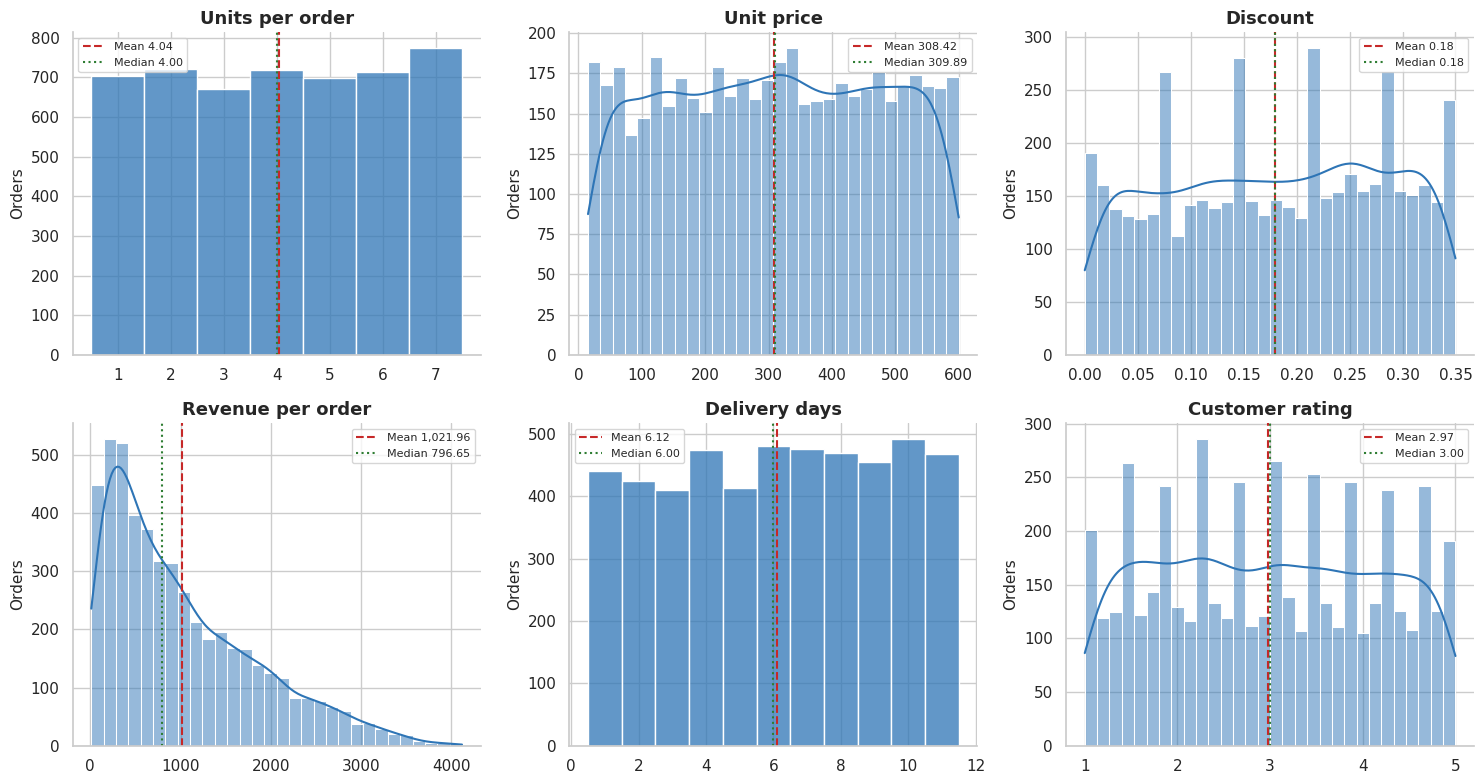

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
specs = [("quantity", True, "Units per order"), ("unit_price", False, "Unit price"), ("discount", False, "Discount"),
         ("revenue", False, "Revenue per order"), ("delivery_days", True, "Delivery days"), ("customer_rating", False, "Customer rating")]
for ax, (col, discrete, label) in zip(axes.ravel(), specs):
    sns.histplot(df[col], discrete=discrete, bins=None if discrete else 30, kde=not discrete, color=BLUE, ax=ax)
    ax.axvline(df[col].mean(), color=RED, linestyle="--", label=f"Mean {df[col].mean():,.2f}")
    ax.axvline(df[col].median(), color=GREEN, linestyle=":", label=f"Median {df[col].median():,.2f}")
    ax.set_title(label); ax.set_xlabel(""); ax.set_ylabel("Orders"); ax.legend(fontsize=8)
finish("02_distributions")

In [12]:
num_cols = ["quantity", "unit_price", "discount", "revenue", "delivery_days", "customer_rating"]
df[num_cols].agg(["mean", "median", "std", "min", "max", "skew"]).T

,mean,median,std,min,max,skew
quantity,4.04,4.00,2.02,1.00,7.00,-0.02
unit_price,308.42,309.89,169.26,15.15,599.96,-0.01
discount,0.18,0.18,0.10,0.00,0.35,-0.07
revenue,"1,021.96",796.65,825.58,11.21,"4,119.33",1.00
delivery_days,6.12,6.00,3.15,1.00,11.00,-0.06
customer_rating,2.97,3.00,1.16,1.00,5.00,0.04


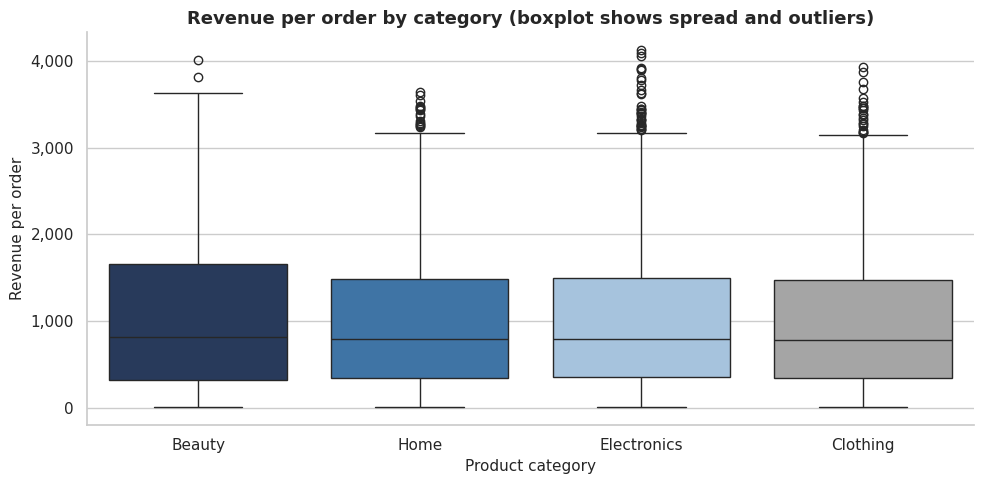

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
order_ = df.groupby("product_category")["revenue"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="product_category", y="revenue", order=order_, palette=[NAVY, BLUE, LIGHT, GREY], ax=ax)
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Revenue per order by category (boxplot shows spread and outliers)")
ax.set_xlabel("Product category"); ax.set_ylabel("Revenue per order")
finish("03_revenue_boxplot")

**Reading the charts:** quantity, discount and rating are spread evenly, while revenue per order is *right-skewed* - most orders are small to medium and a few are very large. That is why the mean order value is higher than the median.

## 6. Product category analysis
*Which categories bring the most revenue, and why?* Revenue = orders x average order value, so both parts are shown.

In [14]:
cat_summary = summarize("product_category").sort_values("revenue", ascending=False)
cat_summary

,revenue,orders,units,avg_order_value,avg_rating,avg_delivery_days,revenue_share_%
product_category,,,,,,,
Electronics,"1,829,899.22",1777,7109,"1,029.77",2.95,6.07,35.81
Clothing,"1,531,931.72",1531,6171,"1,000.61",3.01,6.12,29.98
Home,"982,083.92",969,3949,"1,013.50",2.94,6.15,19.22
Beauty,"765,860.88",723,2995,"1,059.28",3.01,6.20,14.99


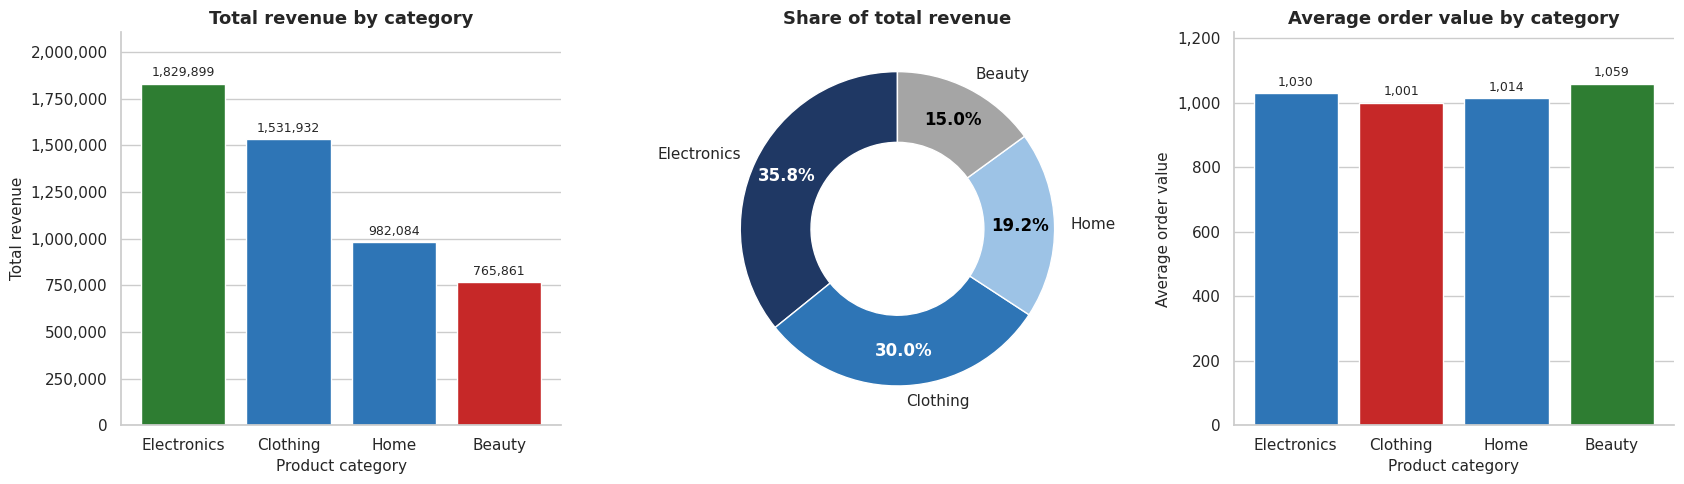

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
bar_on(axes[0], cat_summary["revenue"], "Total revenue by category", "Product category", "Total revenue",
       colors=highlight(cat_summary["revenue"]))
wedges, texts, autotexts = axes[1].pie(cat_summary["revenue"], labels=cat_summary.index, autopct="%1.1f%%", startangle=90,
        colors=[NAVY, BLUE, LIGHT, GREY], wedgeprops={"width": 0.45, "edgecolor": "white"}, pctdistance=0.78)
for t, c in zip(autotexts, ["white", "white", "black", "black"]):
    t.set_color(c); t.set_fontweight("bold")
axes[1].set_title("Share of total revenue")
bar_on(axes[2], cat_summary["avg_order_value"], "Average order value by category", "Product category", "Average order value",
       colors=highlight(cat_summary["avg_order_value"]))
finish("04_category_overview")

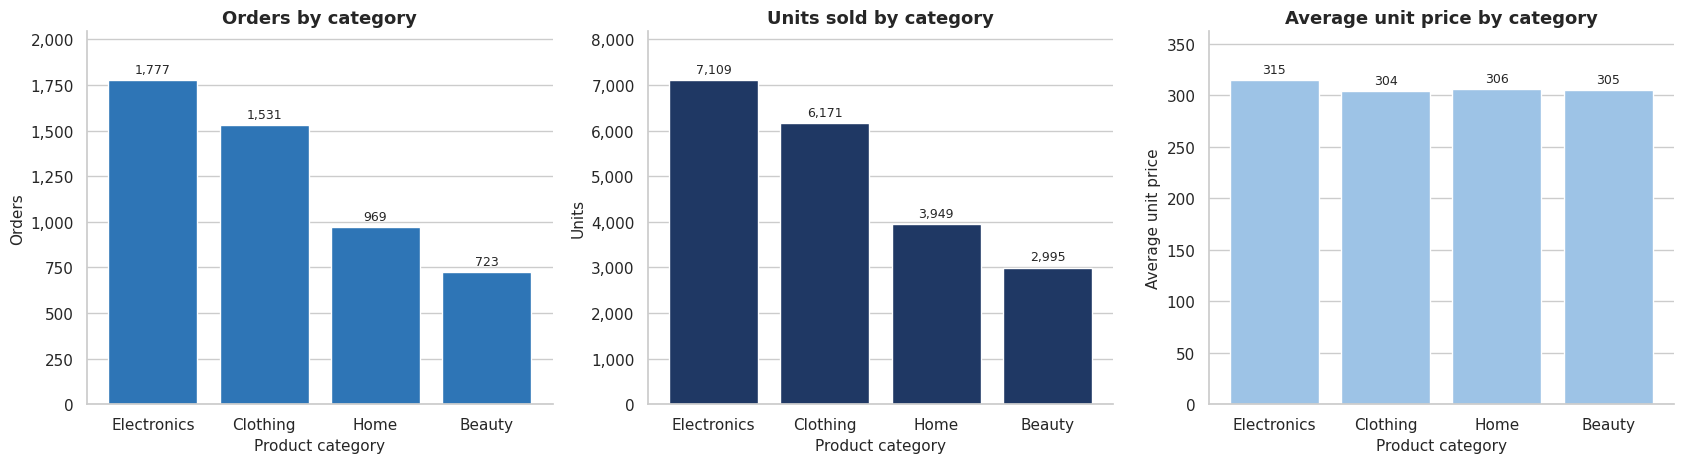

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
bar_on(axes[0], cat_summary["orders"], "Orders by category", "Product category", "Orders", colors=BLUE)
bar_on(axes[1], cat_summary["units"], "Units sold by category", "Product category", "Units", colors=NAVY)
bar_on(axes[2], df.groupby("product_category")["unit_price"].mean().reindex(cat_summary.index),
       "Average unit price by category", "Product category", "Average unit price", colors=LIGHT)
finish("05_category_drivers")

## 7. Regional analysis
*Which region earns the most and the least?*

In [17]:
reg_summary = summarize("region").sort_values("revenue", ascending=False)
best_region, worst_region = reg_summary.index[0], reg_summary.index[-1]
gap = reg_summary["revenue"].max() - reg_summary["revenue"].min()
print(f"Highest revenue: {best_region}  ({reg_summary.loc[best_region, 'revenue']:,.0f})")
print(f"Lowest revenue : {worst_region}  ({reg_summary.loc[worst_region, 'revenue']:,.0f})")
print(f"Gap            : {gap:,.0f}  ({gap / reg_summary['revenue'].sum():.1%} of total revenue)")
reg_summary

Highest revenue: West  (1,345,582)
Lowest revenue : East  (1,236,044)
Gap            : 109,538  (2.1% of total revenue)


,revenue,orders,units,avg_order_value,avg_rating,avg_delivery_days,revenue_share_%
region,,,,,,,
West,"1,345,582.16",1289,5260,"1,043.90",2.96,6.08,26.33
North,"1,281,508.45",1276,5164,"1,004.32",2.99,6.12,25.08
South,"1,246,640.90",1208,4884,"1,031.99",2.97,6.17,24.40
East,"1,236,044.23",1227,4916,"1,007.37",2.97,6.10,24.19


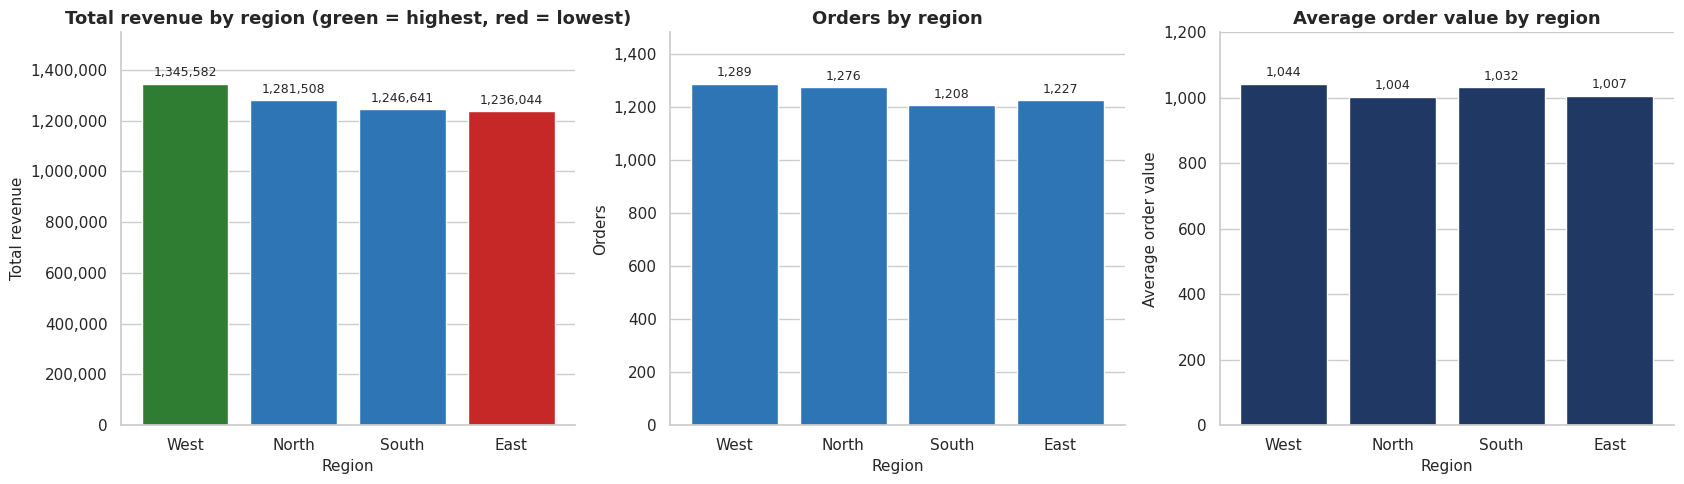

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
bar_on(axes[0], reg_summary["revenue"], "Total revenue by region (green = highest, red = lowest)", "Region", "Total revenue",
       colors=highlight(reg_summary["revenue"]))
bar_on(axes[1], reg_summary["orders"], "Orders by region", "Region", "Orders", colors=BLUE)
bar_on(axes[2], reg_summary["avg_order_value"], "Average order value by region", "Region", "Average order value", colors=NAVY)
finish("06_region_overview")

## 8. Category x Region

In [19]:
cat_reg = df.pivot_table(index="product_category", columns="region", values="revenue", aggfunc="sum")
cat_reg_total = cat_reg.copy()
cat_reg_total["Total"] = cat_reg_total.sum(axis=1)
cat_reg_total.loc["Total"] = cat_reg_total.sum()
cat_reg_total

region,East,North,South,West,Total
product_category,,,,,
Beauty,"174,909.11","186,213.32","191,073.98","213,664.47","765,860.88"
Clothing,"402,582.60","364,659.43","348,363.14","416,326.55","1,531,931.72"
Electronics,"411,803.35","472,450.93","487,055.68","458,589.26","1,829,899.22"
Home,"246,749.17","258,184.77","220,148.10","257,001.88","982,083.92"
Total,"1,236,044.23","1,281,508.45","1,246,640.90","1,345,582.16","5,109,775.74"


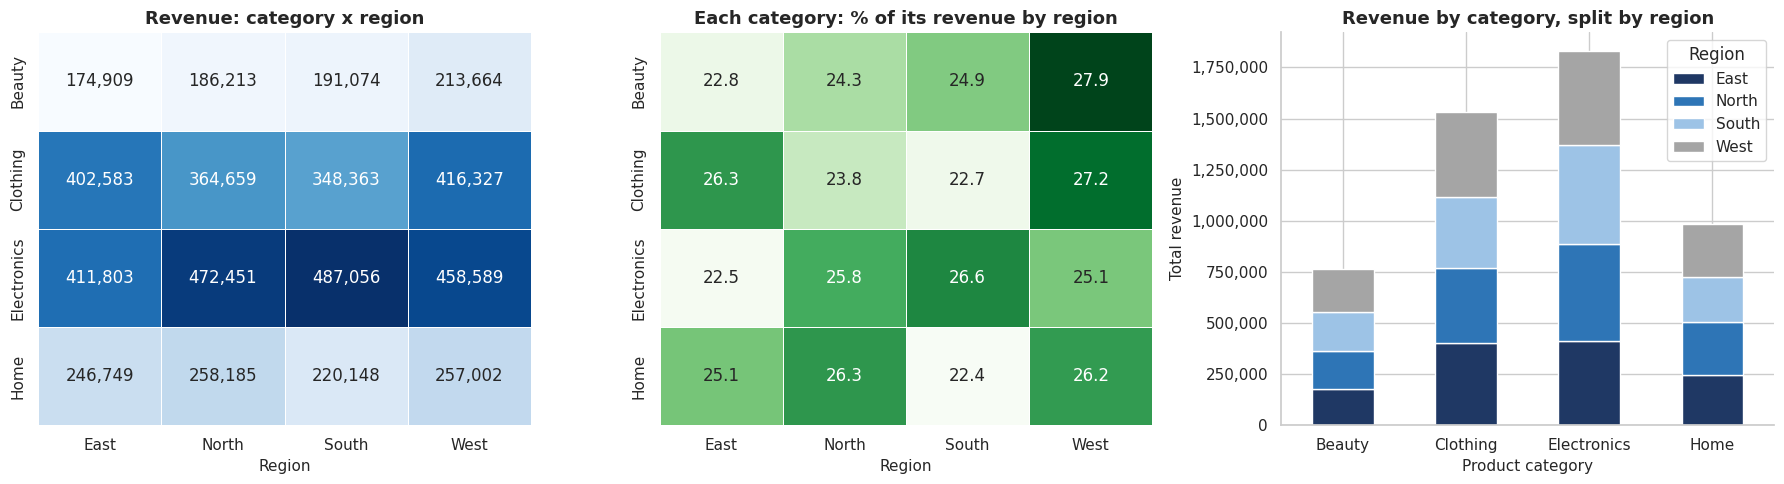

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(cat_reg, annot=True, fmt=",.0f", cmap="Blues", cbar=False, linewidths=0.5, ax=axes[0])
axes[0].set_title("Revenue: category x region"); axes[0].set_xlabel("Region"); axes[0].set_ylabel("")

share_in_cat = cat_reg.div(cat_reg.sum(axis=1), axis=0) * 100
sns.heatmap(share_in_cat, annot=True, fmt=".1f", cmap="Greens", cbar=False, linewidths=0.5, ax=axes[1])
axes[1].set_title("Each category: % of its revenue by region"); axes[1].set_xlabel("Region"); axes[1].set_ylabel("")

cat_reg.plot(kind="bar", stacked=True, ax=axes[2], color=COLORS)
axes[2].yaxis.set_major_formatter(thousands)
axes[2].set_title("Revenue by category, split by region"); axes[2].set_xlabel("Product category"); axes[2].set_ylabel("Total revenue")
axes[2].tick_params(axis="x", rotation=0); axes[2].legend(title="Region")
finish("07_category_by_region")

## 9. Time analysis
*How does revenue change over time?* Yearly, quarterly, monthly and weekday views, a rolling trend and a trend test. The last year is partial, so it is shown separately and never compared with full years.

In [21]:
yearly = (df.groupby("order_year")
            .agg(revenue=("revenue", "sum"), orders=("order_id", "count"), avg_order_value=("revenue", "mean")))
yearly["yoy_growth_%"] = yearly["revenue"].pct_change() * 100
if PARTIAL_YEAR is not None:
    yearly.loc[PARTIAL_YEAR, "yoy_growth_%"] = np.nan          # partial year is not comparable
yearly

,revenue,orders,avg_order_value,yoy_growth_%
order_year,,,,
2022,"371,824.30",365,"1,018.70",NaN
2023,"365,915.79",365,"1,002.51",-1.59
2024,"363,209.13",366,992.37,-0.74
2025,"349,802.33",365,958.36,-3.69
2026,"386,369.69",365,"1,058.55",10.45
2027,"386,151.91",365,"1,057.95",-0.06
2028,"376,844.80",366,"1,029.63",-2.41
2029,"359,239.24",365,984.22,-4.67
2030,"387,884.46",365,"1,062.70",7.97


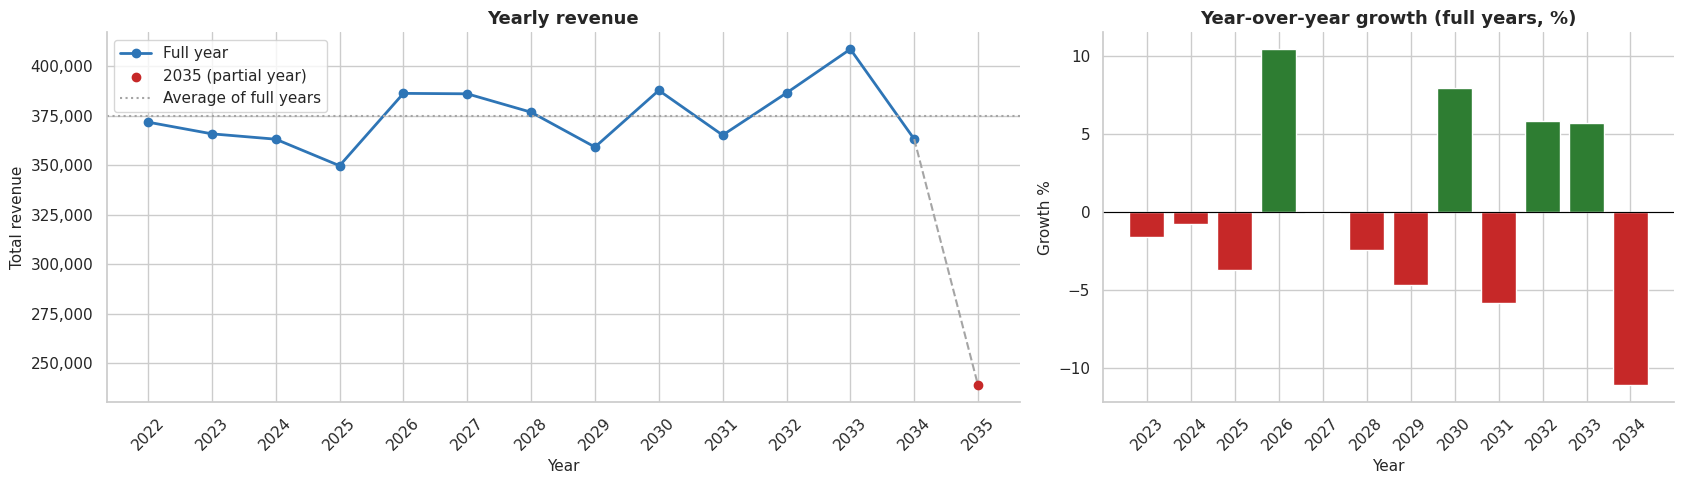

In [22]:
full = yearly.drop(index=PARTIAL_YEAR) if PARTIAL_YEAR is not None else yearly
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(full.index, full["revenue"], marker="o", color=BLUE, linewidth=2, label="Full year")
if PARTIAL_YEAR is not None:
    ax.plot([full.index[-1], PARTIAL_YEAR], [full["revenue"].iloc[-1], yearly.loc[PARTIAL_YEAR, "revenue"]], linestyle="--", color=GREY)
    ax.scatter([PARTIAL_YEAR], [yearly.loc[PARTIAL_YEAR, "revenue"]], color=RED, zorder=3, label=f"{PARTIAL_YEAR} (partial year)")
ax.axhline(full["revenue"].mean(), color=GREY, linestyle=":", label="Average of full years")
ax.yaxis.set_major_formatter(thousands); ax.set_xticks(yearly.index); ax.tick_params(axis="x", rotation=45)
ax.set_title("Yearly revenue"); ax.set_xlabel("Year"); ax.set_ylabel("Total revenue"); ax.legend()

growth = full["yoy_growth_%"].dropna()
axes[1].bar(growth.index.astype(str), growth.values, color=[GREEN if g >= 0 else RED for g in growth.values])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Year-over-year growth (full years, %)"); axes[1].set_xlabel("Year"); axes[1].set_ylabel("Growth %")
axes[1].tick_params(axis="x", rotation=45)
finish("08_yearly_revenue")

In [23]:
quarterly = df.groupby("quarter").agg(revenue=("revenue", "sum"), orders=("order_id", "count"), avg_order_value=("revenue", "mean"))
quarterly.index = [f"Q{q}" for q in quarterly.index]
monthly = (df.groupby("order_month")
             .agg(revenue=("revenue", "sum"), orders=("order_id", "count"), avg_order_value=("revenue", "mean"))
             .reindex(range(1, 13)))
monthly.index = MONTHS
weekday = df.groupby("weekday").agg(revenue=("revenue", "sum"), orders=("order_id", "count"), avg_order_value=("revenue", "mean"))
weekday.index = WEEKDAYS
best_m, worst_m = monthly["revenue"].idxmax(), monthly["revenue"].idxmin()
best_wd, worst_wd = weekday["revenue"].idxmax(), weekday["revenue"].idxmin()
monthly

,revenue,orders,avg_order_value
Jan,"426,374.92",434,982.43
Feb,"413,890.24",395,"1,047.82"
Mar,"425,050.52",434,979.38
Apr,"398,715.16",420,949.32
May,"479,772.55",434,"1,105.47"
Jun,"442,941.58",420,"1,054.62"
Jul,"440,570.72",434,"1,015.14"
Aug,"460,874.78",434,"1,061.92"
Sep,"402,368.11",399,"1,008.44"
Oct,"407,873.12",403,"1,012.09"


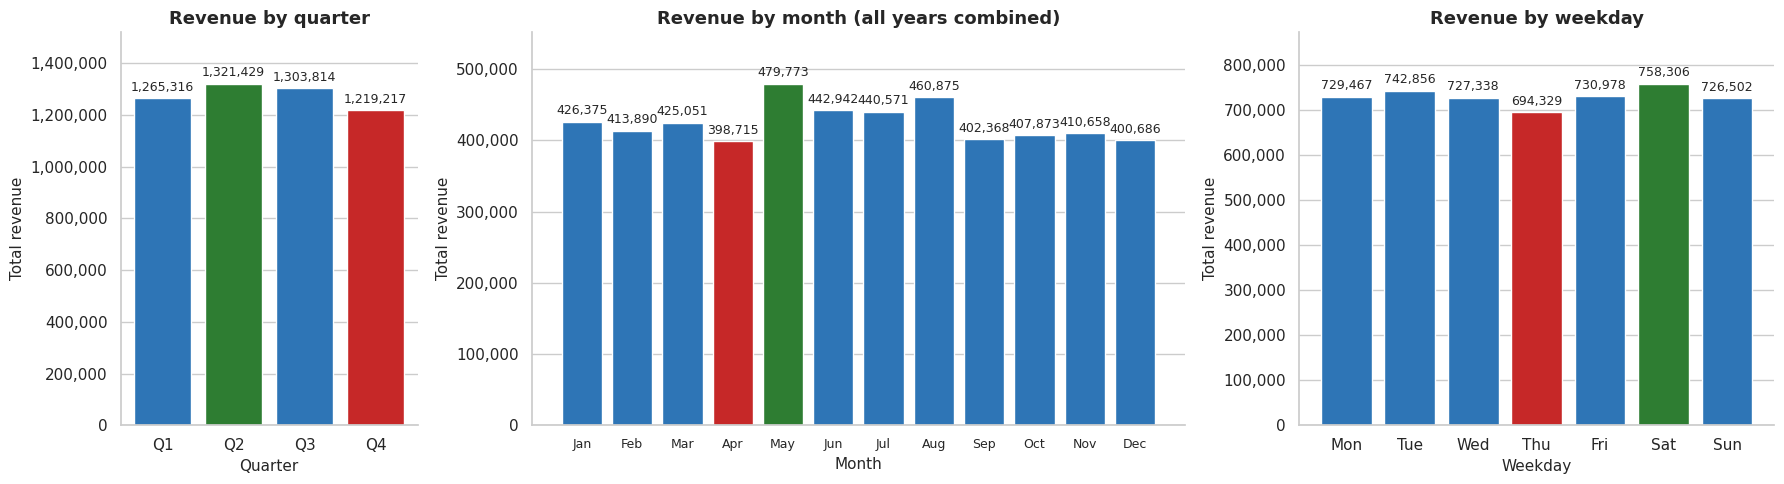

Note: months with more days have more orders, so also compare average order value (next chart).


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 2.2, 1.6]})
bar_on(axes[0], quarterly["revenue"], "Revenue by quarter", "Quarter", "Total revenue", colors=highlight(quarterly["revenue"]))
bar_on(axes[1], monthly["revenue"], "Revenue by month (all years combined)", "Month", "Total revenue", colors=highlight(monthly["revenue"]), fmt="{:,.0f}")
bar_on(axes[2], weekday["revenue"], "Revenue by weekday", "Weekday", "Total revenue", colors=highlight(weekday["revenue"]))
for lab in axes[1].get_xticklabels(): lab.set_fontsize(9)
finish("09_quarter_month_weekday")
print("Note: months with more days have more orders, so also compare average order value (next chart).")

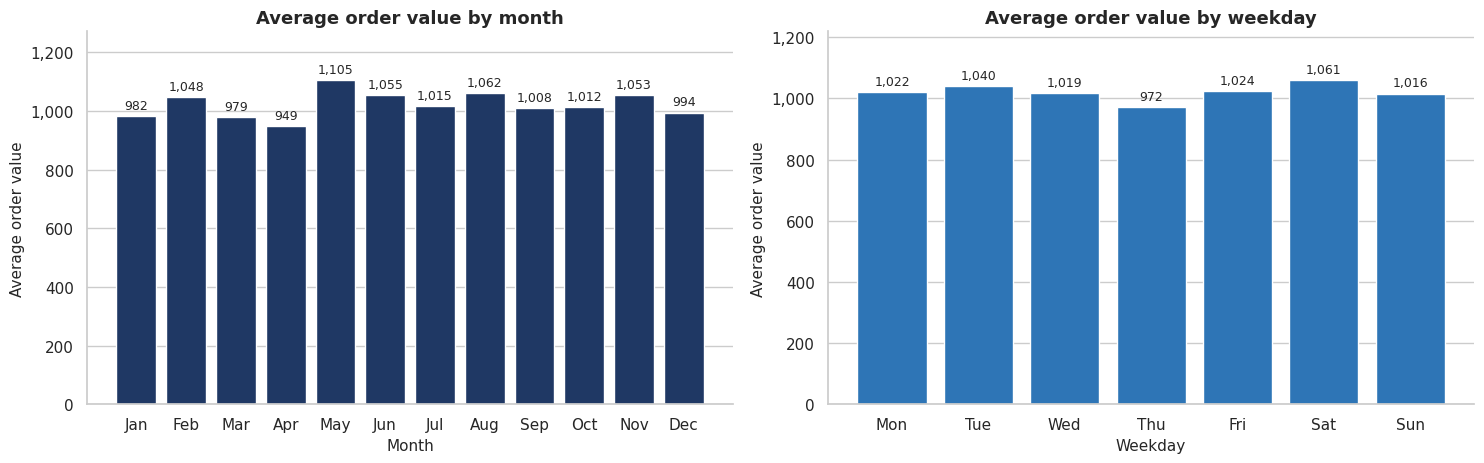

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
bar_on(axes[0], monthly["avg_order_value"], "Average order value by month", "Month", "Average order value", colors=NAVY)
bar_on(axes[1], weekday["avg_order_value"], "Average order value by weekday", "Weekday", "Average order value", colors=BLUE)
finish("10_aov_month_weekday")

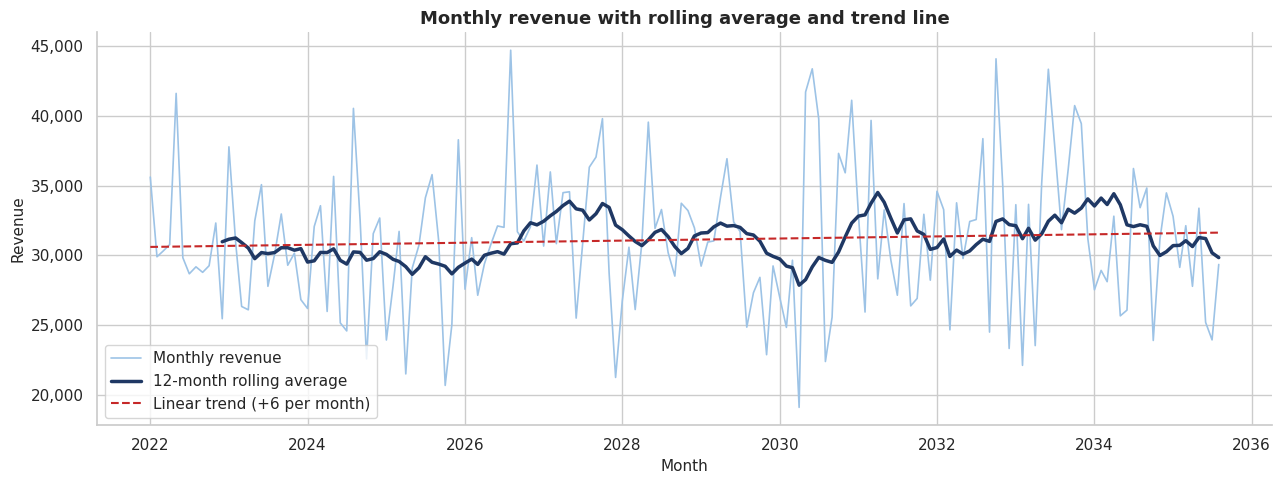

Trend slope: +6.3 per month | R-squared: 0.0035 | p-value: 0.4548


In [26]:
ts = df.set_index("order_date")["revenue"].resample("MS").sum()
last_date = df["order_date"].max()
if last_date.day < last_date.days_in_month:                      # drop the incomplete final month
    ts = ts.iloc[:-1]

x = np.arange(len(ts))
trend = stats.linregress(x, ts.values)
fitted = trend.intercept + trend.slope * x

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(ts.index, ts.values, color=LIGHT, linewidth=1.2, label="Monthly revenue")
ax.plot(ts.index, ts.rolling(12).mean(), color=NAVY, linewidth=2.5, label="12-month rolling average")
ax.plot(ts.index, fitted, color=RED, linestyle="--", label=f"Linear trend ({trend.slope:+,.0f} per month)")
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Monthly revenue with rolling average and trend line"); ax.set_xlabel("Month"); ax.set_ylabel("Revenue"); ax.legend()
finish("11_monthly_trend")
print(f"Trend slope: {trend.slope:+,.1f} per month | R-squared: {trend.rvalue**2:.4f} | p-value: {trend.pvalue:.4f}")

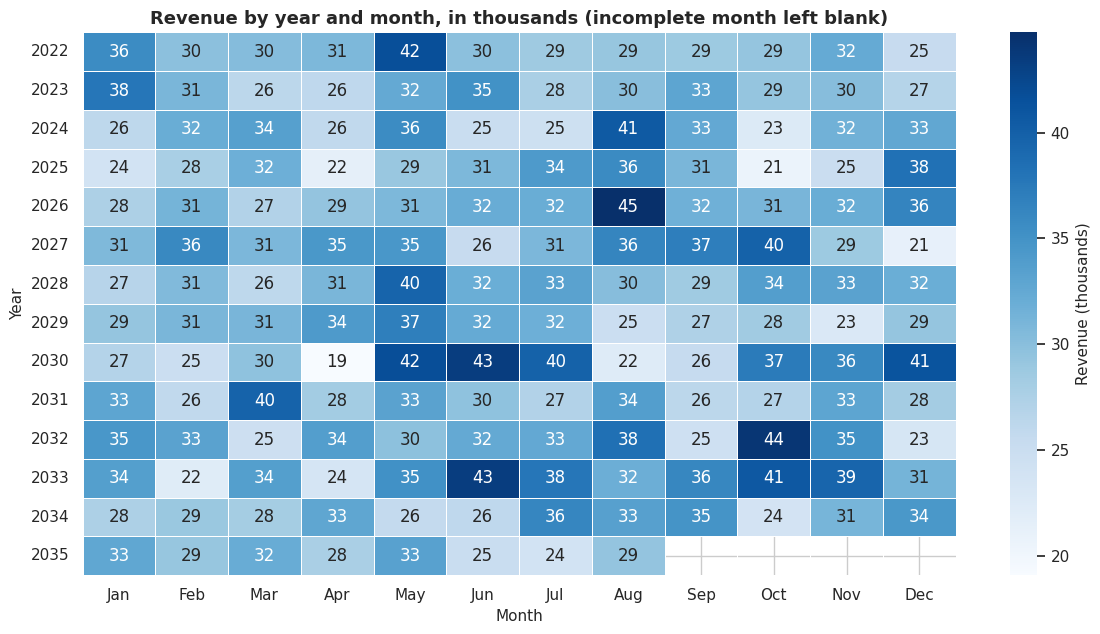

In [27]:
heat = df.pivot_table(index="order_year", columns="order_month", values="revenue", aggfunc="sum")
heat.columns = [MONTHS[m - 1] for m in heat.columns]
if last_date.day < last_date.days_in_month:
    heat.loc[last_date.year, MONTHS[last_date.month - 1]] = np.nan   # incomplete month left blank

fig, ax = plt.subplots(figsize=(12, 6.5))
sns.heatmap(heat / 1000, annot=True, fmt=".0f", cmap="Blues", linewidths=0.5, cbar_kws={"label": "Revenue (thousands)"}, ax=ax)
ax.set_title("Revenue by year and month, in thousands (incomplete month left blank)")
ax.set_xlabel("Month"); ax.set_ylabel("Year")
finish("12_year_month_heatmap")

## 10. Payment methods
*How many orders come through each payment method, and does the choice depend on what customers buy?*

In [28]:
pay = (df.groupby("payment_method")
         .agg(orders=("order_id", "count"), units=("quantity", "sum"), revenue=("revenue", "sum"),
              avg_order_value=("revenue", "mean"), avg_rating=("customer_rating", "mean"))
         .sort_values("orders", ascending=False))
pay["order_share_%"] = pay["orders"] / pay["orders"].sum() * 100
pay

,orders,units,revenue,avg_order_value,avg_rating,order_share_%
payment_method,,,,,,
Card,2270,9333,"2,366,248.20","1,042.40",3.02,45.40
COD,1774,7047,"1,788,408.44","1,008.12",2.94,35.48
Wallet,956,3844,"955,119.10",999.08,2.93,19.12


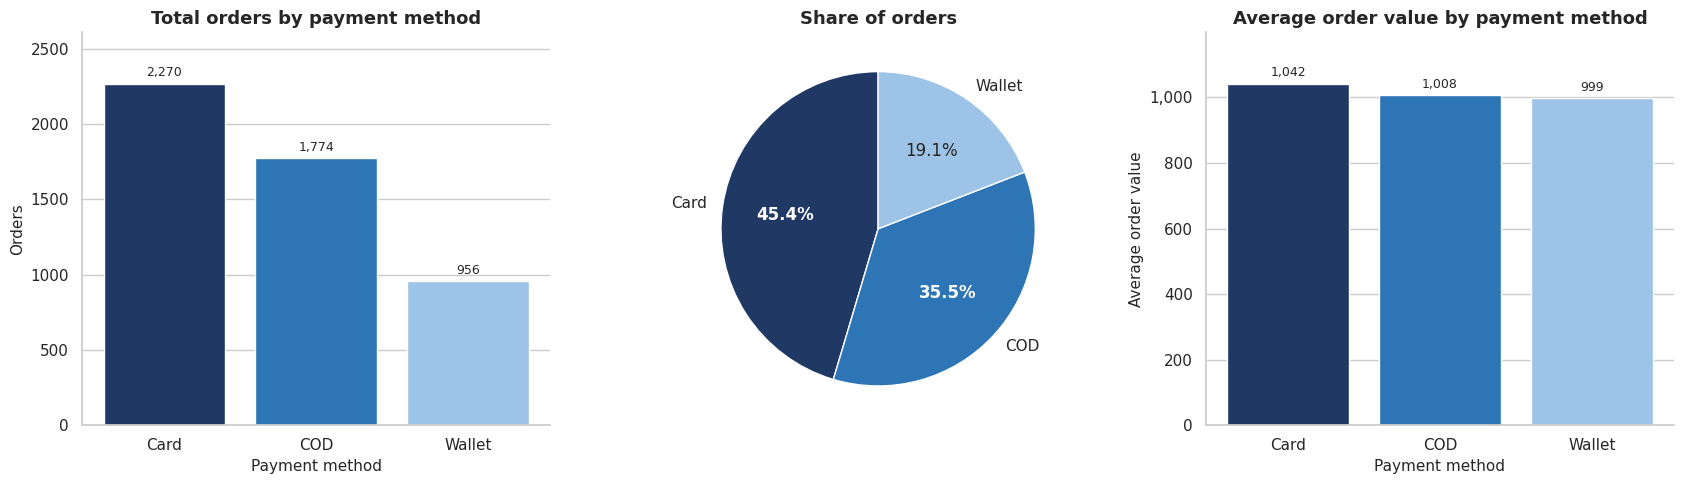

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
bar_on(axes[0], pay["orders"], "Total orders by payment method", "Payment method", "Orders", colors=[NAVY, BLUE, LIGHT], money=False)
_, _, pct = axes[1].pie(pay["orders"], labels=pay.index, autopct="%1.1f%%", startangle=90, colors=[NAVY, BLUE, LIGHT],
                        wedgeprops={"edgecolor": "white"})
for t in pct[:2]:
    t.set_color("white"); t.set_fontweight("bold")
axes[1].set_title("Share of orders")
bar_on(axes[2], pay["avg_order_value"], "Average order value by payment method", "Payment method", "Average order value", colors=[NAVY, BLUE, LIGHT])
finish("13_payment_overview")

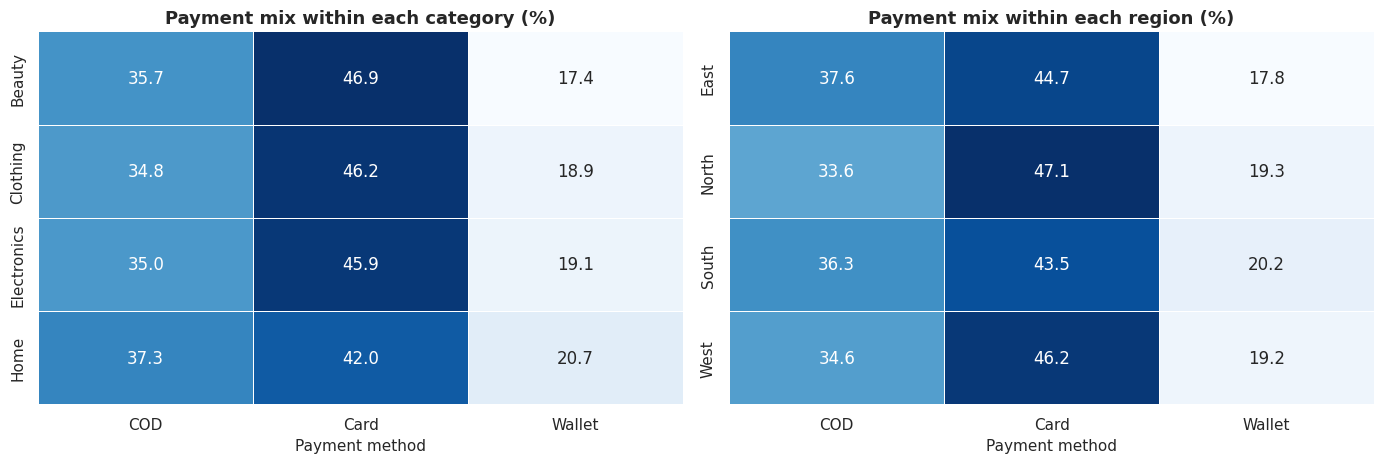

In [30]:
pay_cat = pd.crosstab(df["product_category"], df["payment_method"], normalize="index") * 100
pay_reg = pd.crosstab(df["region"], df["payment_method"], normalize="index") * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(pay_cat, annot=True, fmt=".1f", cmap="Blues", cbar=False, linewidths=0.5, ax=axes[0])
axes[0].set_title("Payment mix within each category (%)"); axes[0].set_xlabel("Payment method"); axes[0].set_ylabel("")
sns.heatmap(pay_reg, annot=True, fmt=".1f", cmap="Blues", cbar=False, linewidths=0.5, ax=axes[1])
axes[1].set_title("Payment mix within each region (%)"); axes[1].set_xlabel("Payment method"); axes[1].set_ylabel("")
finish("14_payment_mix")

## 11. Pricing and discounts
*Do discounts bring bigger or more orders - and how much money do they give away?* "Revenue leakage" means the discount amount as a share of gross sales.

In [31]:
price = (df.groupby("price_band", observed=True)
           .agg(orders=("order_id", "count"), revenue=("revenue", "sum"), avg_order_value=("revenue", "mean"),
                avg_quantity=("quantity", "mean"), avg_rating=("customer_rating", "mean")))
disc = (df.groupby("discount_band", observed=True)
          .agg(orders=("order_id", "count"), revenue=("revenue", "sum"), avg_order_value=("revenue", "mean"),
               avg_quantity=("quantity", "mean"), avg_rating=("customer_rating", "mean"),
               discount_given=("discount_amount", "sum"), gross_sales=("gross_sales", "sum")))
disc["leakage_%"] = disc["discount_given"] / disc["gross_sales"] * 100
leak_cat = (df.groupby("product_category").agg(discount_given=("discount_amount", "sum"), gross=("gross_sales", "sum")))
leak_cat["leakage_%"] = leak_cat["discount_given"] / leak_cat["gross"] * 100
print("Price bands (quartiles of unit price):")
display(price)
print("Discount bands:")
disc

Price bands (quartiles of unit price):


,orders,revenue,avg_order_value,avg_quantity,avg_rating
price_band,,,,,
Low,1250,"364,529.74",291.62,4.04,2.94
Mid-low,1250,"989,446.71",791.56,4.08,2.97
Mid-high,1250,"1,566,453.56","1,253.16",4.02,3.02
High,1250,"2,189,345.73","1,751.48",4.05,2.96


Discount bands:


,orders,revenue,avg_order_value,avg_quantity,avg_rating,discount_given,gross_sales,leakage_%
discount_band,,,,,,,,
0-9%,1260,"1,480,688.73","1,175.15",4.05,2.96,"71,242.34","1,551,931.16",4.59
10-19%,1413,"1,487,394.42","1,052.65",4.02,2.95,"253,084.03","1,740,478.45",14.54
20-29%,1476,"1,415,161.56",958.78,4.11,2.98,"459,298.63","1,874,460.11",24.50
30%+,851,"726,531.03",853.74,3.98,3.01,"346,621.07","1,073,152.24",32.30


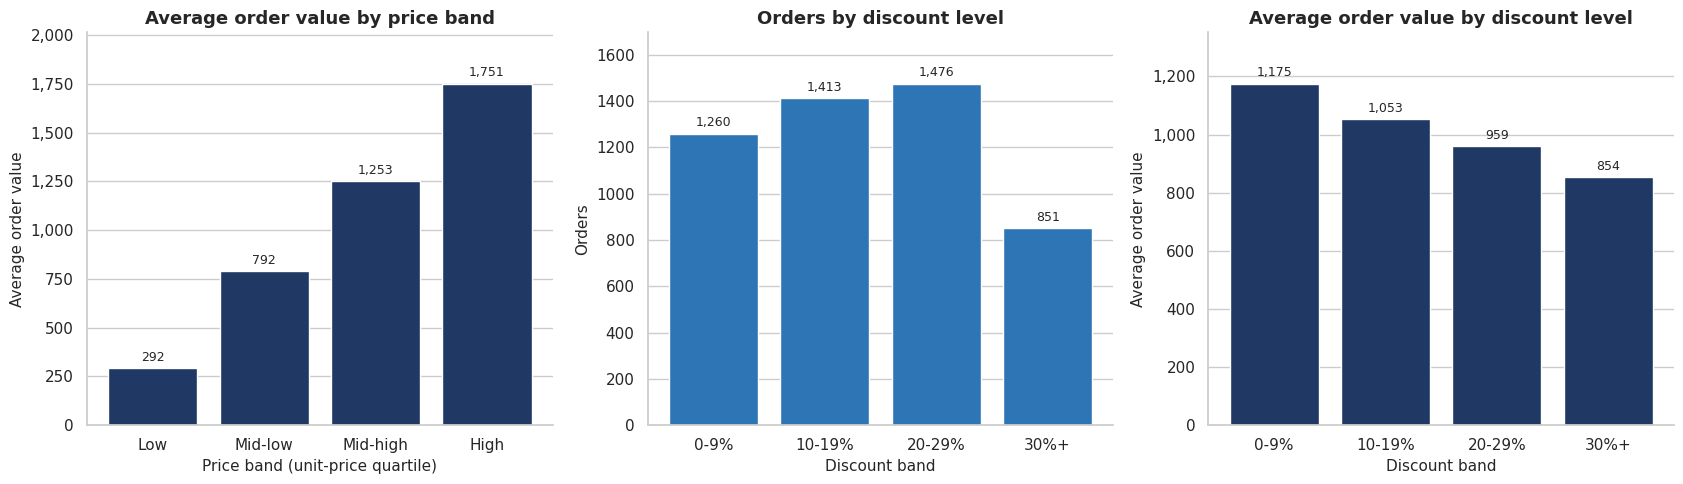

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
bar_on(axes[0], price["avg_order_value"], "Average order value by price band", "Price band (unit-price quartile)", "Average order value", colors=NAVY)
bar_on(axes[1], disc["orders"], "Orders by discount level", "Discount band", "Orders", colors=BLUE, money=False)
bar_on(axes[2], disc["avg_order_value"], "Average order value by discount level", "Discount band", "Average order value", colors=NAVY)
finish("15_price_discount_bands")

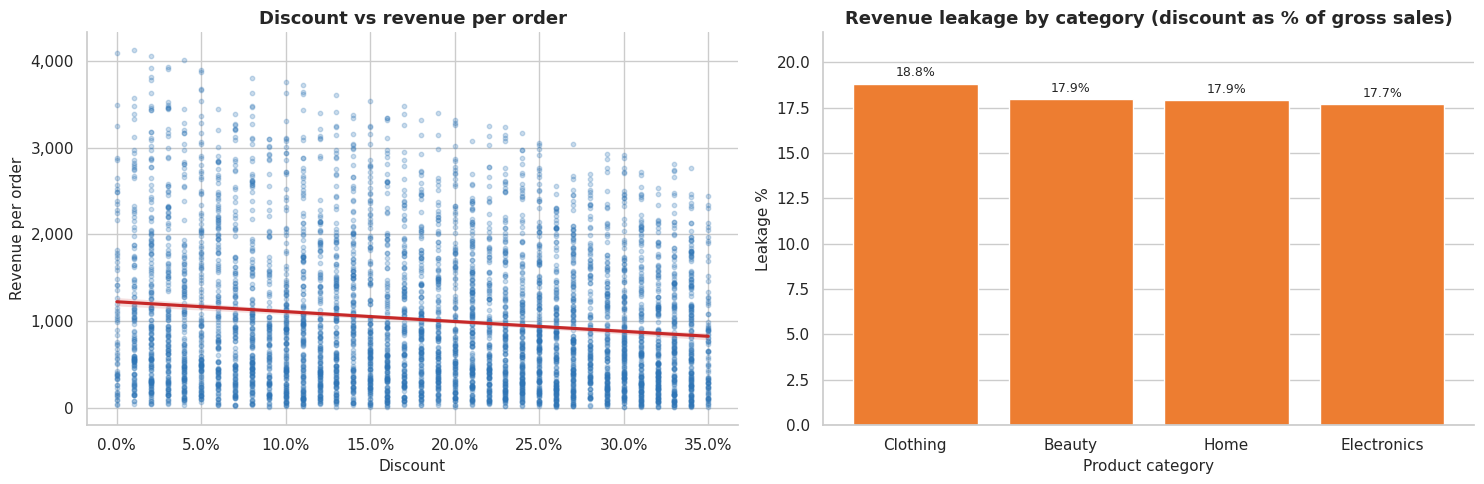

Total discount given: 1,130,246 = 18.1% of gross sales (6,240,022).


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.regplot(data=df, x="discount", y="revenue", scatter_kws={"alpha": 0.25, "s": 10, "color": BLUE}, line_kws={"color": RED}, ax=axes[0])
axes[0].xaxis.set_major_formatter(ticker.PercentFormatter(1.0)); axes[0].yaxis.set_major_formatter(thousands)
axes[0].set_title("Discount vs revenue per order"); axes[0].set_xlabel("Discount"); axes[0].set_ylabel("Revenue per order")
bar_on(axes[1], leak_cat["leakage_%"].sort_values(ascending=False), "Revenue leakage by category (discount as % of gross sales)",
       "Product category", "Leakage %", colors=ORANGE, fmt="{:.1f}%", money=False)
finish("16_discount_effect_leakage")
print(f"Total discount given: {discount_total:,.0f} = {discount_total / gross_total:.1%} of gross sales ({gross_total:,.0f}).")

## 12. Customer analysis and RFM segmentation
*Who are the best customers?* RFM scores every customer on **R**ecency (days since last order), **F**requency (number of orders) and **M**onetary value (total revenue), each from 1 (worst) to 5 (best).

In [34]:
snapshot = df["order_date"].max() + pd.Timedelta(days=1)
rfm = (df.groupby("customer_id")
         .agg(recency=("order_date", lambda s: (snapshot - s.max()).days), frequency=("order_id", "count"),
              monetary=("revenue", "sum"), avg_rating=("customer_rating", "mean")))

rfm["R"] = pd.qcut(rfm["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)   # recent = high score
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["score"] = rfm["R"] + rfm["F"] + rfm["M"]


def segment(score):
    if score >= 12: return "Champions"
    if score >= 10: return "Loyal"
    if score >= 8:  return "Potential"
    if score >= 6:  return "At risk"
    return "Needs attention"


SEG_ORDER = ["Champions", "Loyal", "Potential", "At risk", "Needs attention"]
rfm["segment"] = rfm["score"].apply(segment)

seg = (rfm.groupby("segment")
          .agg(customers=("score", "count"), avg_recency_days=("recency", "mean"), avg_orders=("frequency", "mean"),
               avg_revenue=("monetary", "mean"), total_revenue=("monetary", "sum"))
          .reindex(SEG_ORDER))
seg["customer_share_%"] = seg["customers"] / seg["customers"].sum() * 100
seg["revenue_share_%"] = seg["total_revenue"] / seg["total_revenue"].sum() * 100
seg

,customers,avg_recency_days,avg_orders,avg_revenue,total_revenue,customer_share_%,revenue_share_%
segment,,,,,,,
Champions,279,372.37,7.66,"8,355.27","2,331,119.27",28.21,45.62
Loyal,168,646.30,5.70,"5,909.66","992,823.28",16.99,19.43
Potential,189,958.06,4.64,"4,644.22","877,758.23",19.11,17.18
At risk,171,"1,089.15",3.42,"3,256.68","556,892.11",17.29,10.90
Needs attention,182,"2,216.27",2.44,"1,929.58","351,182.85",18.40,6.87


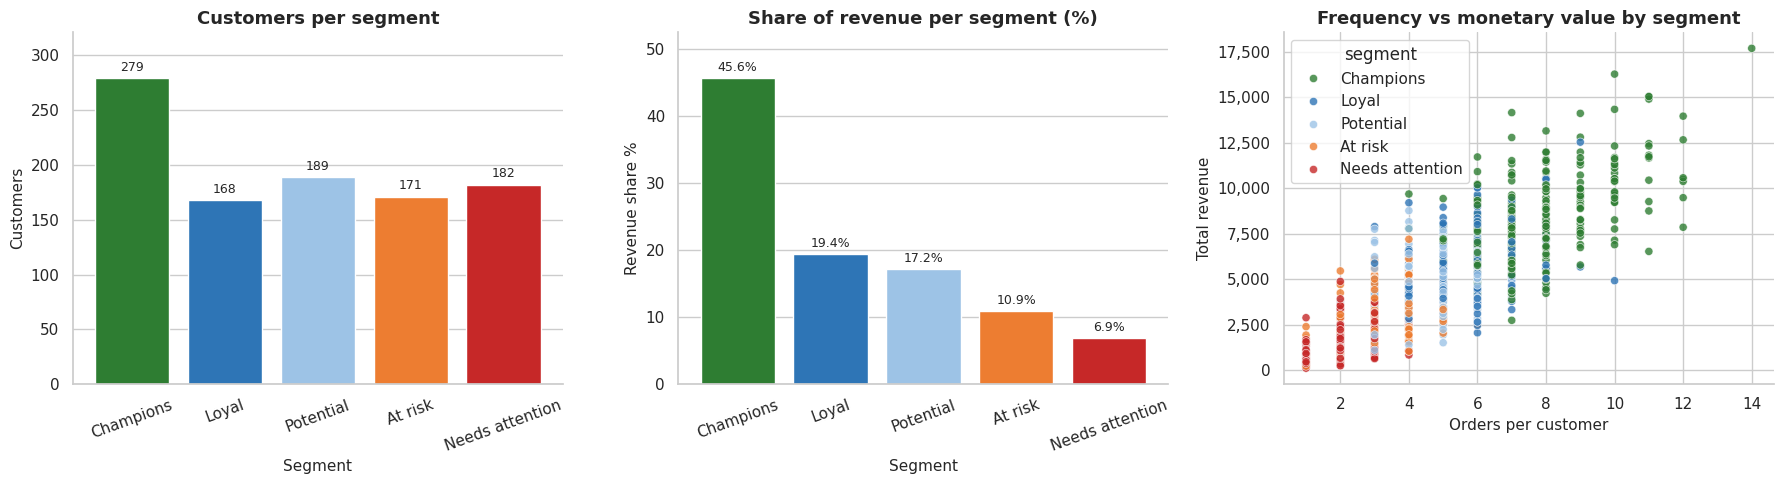

In [35]:
seg_colors = [GREEN, BLUE, LIGHT, ORANGE, RED]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
bar_on(axes[0], seg["customers"], "Customers per segment", "Segment", "Customers", colors=seg_colors, money=False)
bar_on(axes[1], seg["revenue_share_%"], "Share of revenue per segment (%)", "Segment", "Revenue share %", colors=seg_colors, fmt="{:.1f}%", money=False)
sns.scatterplot(data=rfm.reset_index(), x="frequency", y="monetary", hue="segment", hue_order=SEG_ORDER, palette=seg_colors, s=35, alpha=0.8, ax=axes[2])
axes[2].yaxis.set_major_formatter(thousands)
axes[2].set_title("Frequency vs monetary value by segment"); axes[2].set_xlabel("Orders per customer"); axes[2].set_ylabel("Total revenue")
for ax in axes[:2]: ax.tick_params(axis="x", rotation=20)
finish("17_rfm_segments")

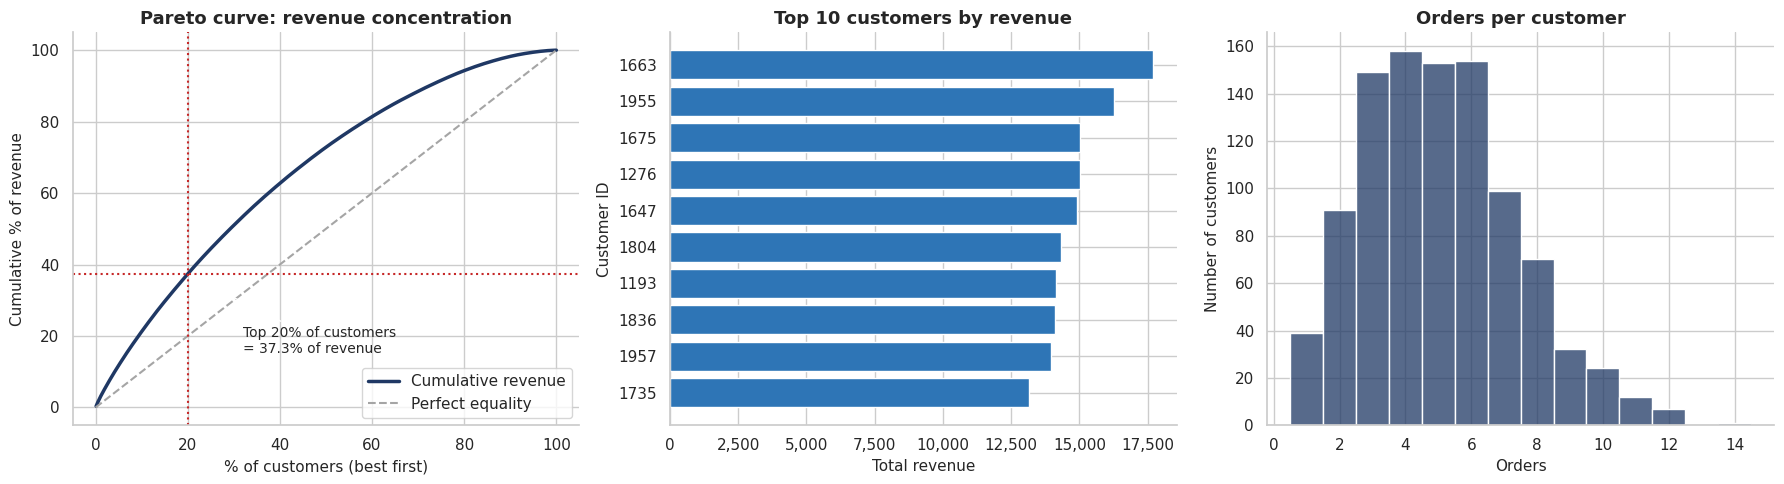

Unique customers: 989 | repeat customers: 96.1% | avg orders per customer: 5.06


,recency,frequency,monetary,avg_rating,segment
customer_id,,,,,
1663,88,14,"17,680.69",2.75,Champions
1955,984,10,"16,265.15",3.49,Champions
1675,54,11,"15,036.46",2.98,Champions
1276,93,11,"15,023.71",3.04,Champions
1647,61,11,"14,894.97",3.03,Champions
1804,1263,10,"14,330.98",3.04,Champions
1193,52,7,"14,151.65",3.27,Champions
1836,112,9,"14,110.78",3.31,Champions
1957,153,12,"13,956.95",3.18,Champions


In [36]:
cust_sorted = rfm["monetary"].sort_values(ascending=False)
cum_rev = cust_sorted.cumsum() / cust_sorted.sum() * 100
cum_cust = np.arange(1, len(cust_sorted) + 1) / len(cust_sorted) * 100
top20_share = cust_sorted.head(int(len(cust_sorted) * 0.2)).sum() / cust_sorted.sum() * 100
repeat_rate = (rfm["frequency"] > 1).mean() * 100

top10 = rfm.sort_values("monetary", ascending=False).head(10)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(cum_cust, cum_rev.values, color=NAVY, linewidth=2.5, label="Cumulative revenue")
axes[0].plot([0, 100], [0, 100], color=GREY, linestyle="--", label="Perfect equality")
axes[0].axvline(20, color=RED, linestyle=":"); axes[0].axhline(top20_share, color=RED, linestyle=":")
axes[0].annotate(f"Top 20% of customers\n= {top20_share:.1f}% of revenue", xy=(20, top20_share), xytext=(32, top20_share - 22),
                 arrowprops={"arrowstyle": "->"}, fontsize=10)
axes[0].set_title("Pareto curve: revenue concentration"); axes[0].set_xlabel("% of customers (best first)"); axes[0].set_ylabel("Cumulative % of revenue"); axes[0].legend(loc="lower right")

t10 = top10.iloc[::-1]
axes[1].barh(t10.index.astype(str), t10["monetary"], color=BLUE)
axes[1].xaxis.set_major_formatter(thousands)
axes[1].set_title("Top 10 customers by revenue"); axes[1].set_xlabel("Total revenue"); axes[1].set_ylabel("Customer ID")

sns.histplot(rfm["frequency"], discrete=True, color=NAVY, ax=axes[2])
axes[2].set_title("Orders per customer"); axes[2].set_xlabel("Orders"); axes[2].set_ylabel("Number of customers")
finish("18_customer_concentration")
print(f"Unique customers: {len(rfm):,} | repeat customers: {repeat_rate:.1f}% | avg orders per customer: {rfm['frequency'].mean():.2f}")
top10[["recency", "frequency", "monetary", "avg_rating", "segment"]]

## 13. Customer experience
*How satisfied are customers, and what (if anything) moves satisfaction?* Late delivery is defined as slower than the 75th percentile of delivery time.

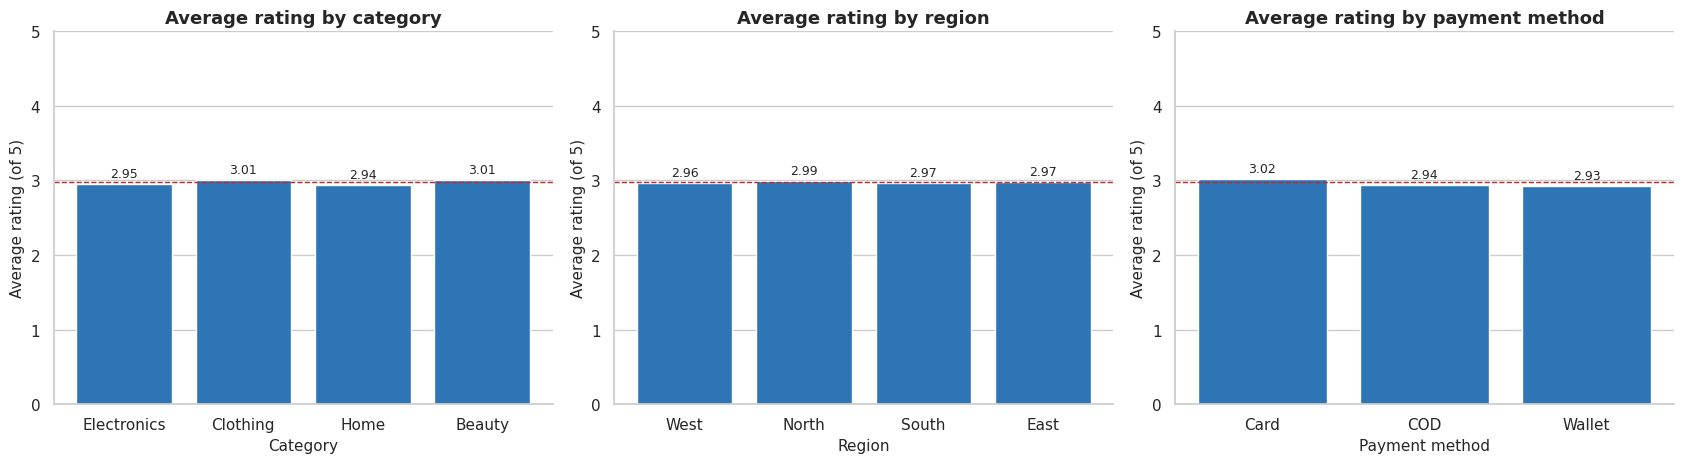

In [37]:
late_cut = df["delivery_days"].quantile(0.75)
df["late_delivery"] = df["delivery_days"] > late_cut
df["low_rating"] = df["customer_rating"] < 3

rating_cat = df.groupby("product_category")["customer_rating"].mean().reindex(cat_summary.index)
rating_reg = df.groupby("region")["customer_rating"].mean().reindex(reg_summary.index)
rating_pay = df.groupby("payment_method")["customer_rating"].mean().reindex(pay.index)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (s, lab) in zip(axes, [(rating_cat, "category"), (rating_reg, "region"), (rating_pay, "payment method")]):
    bar_on(ax, s, f"Average rating by {lab}", lab.capitalize(), "Average rating (of 5)", colors=BLUE, fmt="{:.2f}", money=False)
    ax.set_ylim(0, 5); ax.axhline(df["customer_rating"].mean(), color=RED, linestyle="--", linewidth=1)
finish("19_rating_by_group")

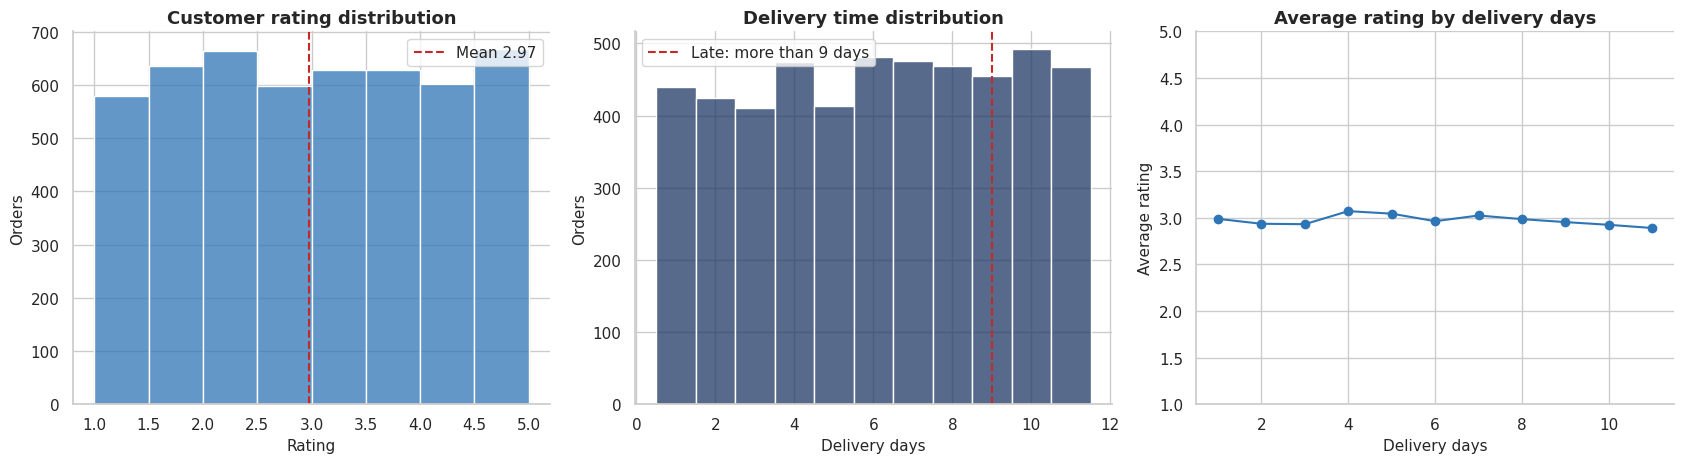

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.histplot(df["customer_rating"], bins=np.arange(1, 5.01, 0.5), color=BLUE, ax=axes[0])
axes[0].axvline(df["customer_rating"].mean(), color=RED, linestyle="--", label=f"Mean {df['customer_rating'].mean():.2f}")
axes[0].set_title("Customer rating distribution"); axes[0].set_xlabel("Rating"); axes[0].set_ylabel("Orders"); axes[0].legend()

sns.histplot(df["delivery_days"], discrete=True, color=NAVY, ax=axes[1])
axes[1].axvline(late_cut, color=RED, linestyle="--", label=f"Late: more than {late_cut:.0f} days")
axes[1].set_title("Delivery time distribution"); axes[1].set_xlabel("Delivery days"); axes[1].set_ylabel("Orders"); axes[1].legend()

rating_by_days = df.groupby("delivery_days")["customer_rating"].mean()
axes[2].plot(rating_by_days.index, rating_by_days.values, marker="o", color=BLUE)
axes[2].set_ylim(1, 5)
axes[2].set_title("Average rating by delivery days"); axes[2].set_xlabel("Delivery days"); axes[2].set_ylabel("Average rating")
finish("20_rating_delivery")

,orders,avg_rating,low_rating_share
On time,4041,2.99,48.92
Late,959,2.91,52.14


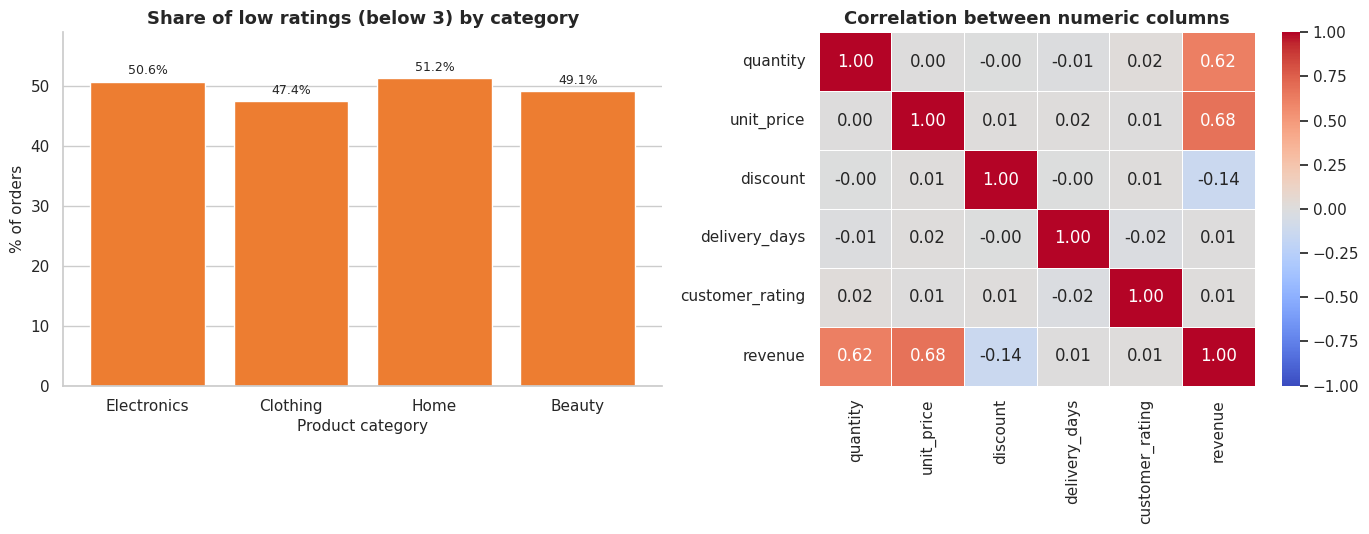

In [39]:
late_summary = df.groupby("late_delivery").agg(orders=("order_id", "count"), avg_rating=("customer_rating", "mean"),
                                               low_rating_share=("low_rating", "mean"))
late_summary.index = ["On time", "Late"]
late_summary["low_rating_share"] *= 100
display(late_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
low_cat = df.groupby("product_category")["low_rating"].mean().mul(100).reindex(cat_summary.index)
bar_on(axes[0], low_cat, "Share of low ratings (below 3) by category", "Product category", "% of orders", colors=ORANGE, fmt="{:.1f}%", money=False)
corr_cols = ["quantity", "unit_price", "discount", "delivery_days", "customer_rating", "revenue"]
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5, ax=axes[1])
axes[1].set_title("Correlation between numeric columns")
finish("21_low_ratings_correlation")

## 14. Statistical tests
Differences in a chart can be real or just random noise. Each test below starts from a *null hypothesis* of "no difference / no relationship"; a **p-value below 0.05** means the null is rejected and the pattern is statistically significant.

In [40]:
rows = []
def add(test, null, stat, p, note=""):
    rows.append({"Test": test, "Null hypothesis": null, "Statistic": f"{stat:.3f}",
                 "p-value": "<0.0001" if p < 0.0001 else f"{p:.4f}",
                 "Result (5% level)": "Significant" if p < 0.05 else "Not significant"})

groups = lambda col, by: [g[col].values for _, g in df.groupby(by)]
f, p = stats.f_oneway(*groups("revenue", "product_category")); add("ANOVA: revenue by category", "Mean revenue per order is equal in all categories", f, p)
f, p = stats.f_oneway(*groups("revenue", "region")); add("ANOVA: revenue by region", "Mean revenue per order is equal in all regions", f, p)
f, p = stats.f_oneway(*groups("customer_rating", "product_category")); add("ANOVA: rating by category", "Mean rating is equal in all categories", f, p)
f, p = stats.f_oneway(*groups("customer_rating", "region")); add("ANOVA: rating by region", "Mean rating is equal in all regions", f, p)
chi, p, dof, _ = stats.chi2_contingency(pd.crosstab(df["payment_method"], df["product_category"])); add("Chi-square: payment x category", "Payment method is independent of category", chi, p)
chi, p, dof, _ = stats.chi2_contingency(pd.crosstab(df["payment_method"], df["region"])); add("Chi-square: payment x region", "Payment method is independent of region", chi, p)
r, p = stats.pearsonr(df["delivery_days"], df["customer_rating"]); add("Pearson: delivery days vs rating", "No linear relationship", r, p)
r, p = stats.spearmanr(df["discount"], df["quantity"]); add("Spearman: discount vs quantity", "Higher discounts do not change quantity", r, p)
t, p = stats.ttest_ind(df.loc[df["discount"] >= 0.2, "revenue"], df.loc[df["discount"] < 0.2, "revenue"], equal_var=False)
add("Welch t-test: revenue, discount >= 20% vs < 20%", "Mean revenue per order is the same", t, p)
t, p = stats.ttest_ind(df.loc[df["late_delivery"], "customer_rating"], df.loc[~df["late_delivery"], "customer_rating"], equal_var=False)
add("Welch t-test: rating, late vs on-time delivery", "Late delivery does not change rating", t, p)
add("Linear trend: monthly revenue over time", "Monthly revenue has no trend", trend.slope, trend.pvalue)

tests = pd.DataFrame(rows)
tests

,Test,Null hypothesis,Statistic,p-value,Result (5% level)
0,ANOVA: revenue by category,Mean revenue per order is equal in all categories,0.921,0.4299,Not significant
1,ANOVA: revenue by region,Mean revenue per order is equal in all regions,0.685,0.5614,Not significant
2,ANOVA: rating by category,Mean rating is equal in all categories,1.088,0.3528,Not significant
3,ANOVA: rating by region,Mean rating is equal in all regions,0.178,0.9111,Not significant
4,Chi-square: payment x category,Payment method is independent of category,6.783,0.3414,Not significant
5,Chi-square: payment x region,Payment method is independent of region,7.221,0.3009,Not significant
6,Pearson: delivery days vs rating,No linear relationship,-0.018,0.2127,Not significant
7,Spearman: discount vs quantity,Higher discounts do not change quantity,-0.004,0.7656,Not significant
8,"Welch t-test: revenue, discount >= 20% vs < 20%",Mean revenue per order is the same,-8.285,<0.0001,Significant
9,"Welch t-test: rating, late vs on-time delivery",Late delivery does not change rating,-1.987,0.0472,Significant


In [41]:
sig = tests["Result (5% level)"].eq("Significant")
print(f"{sig.sum()} of {len(tests)} tests are significant:")
for _, r in tests[sig].iterrows():
    print(f"  - {r['Test']} (p = {r['p-value']})")
print("\nNot significant (differences are consistent with random variation):")
for _, r in tests[~sig].iterrows():
    print(f"  - {r['Test']} (p = {r['p-value']})")

2 of 11 tests are significant:
  - Welch t-test: revenue, discount >= 20% vs < 20% (p = <0.0001)
  - Welch t-test: rating, late vs on-time delivery (p = 0.0472)

Not significant (differences are consistent with random variation):
  - ANOVA: revenue by category (p = 0.4299)
  - ANOVA: revenue by region (p = 0.5614)
  - ANOVA: rating by category (p = 0.3528)
  - ANOVA: rating by region (p = 0.9111)
  - Chi-square: payment x category (p = 0.3414)
  - Chi-square: payment x region (p = 0.3009)
  - Pearson: delivery days vs rating (p = 0.2127)
  - Spearman: discount vs quantity (p = 0.7656)
  - Linear trend: monthly revenue over time (p = 0.4548)


## 15. Insights

In [42]:
top_cat, low_cat_name = cat_summary.index[0], cat_summary.index[-1]
top_pay = pay.index[0]
r_del = df["customer_rating"].corr(df["delivery_days"])
full_years = yearly.drop(index=PARTIAL_YEAR) if PARTIAL_YEAR is not None else yearly
cod_share = pay.loc["COD", "order_share_%"] if "COD" in pay.index else float("nan")
cat_p = float(tests.loc[0, "p-value"].replace("<", "")) if tests.loc[0, "p-value"].startswith("<") else float(tests.loc[0, "p-value"])
champ = seg.loc["Champions"]

insights = [
    f"REVENUE DRIVER: {top_cat} brings {cat_summary.loc[top_cat, 'revenue_share_%']:.1f}% of revenue and {low_cat_name} only "
    f"{cat_summary.loc[low_cat_name, 'revenue_share_%']:.1f}%. The gap comes from order volume ({cat_summary.loc[top_cat, 'orders']:,} vs "
    f"{cat_summary.loc[low_cat_name, 'orders']:,} orders), not price: average order value is similar "
    f"({cat_summary.loc[top_cat, 'avg_order_value']:,.0f} vs {cat_summary.loc[low_cat_name, 'avg_order_value']:,.0f}; ANOVA p = {tests.loc[0, 'p-value']}).",
    f"REGIONS: {best_region} leads ({reg_summary.loc[best_region, 'revenue']:,.0f}) and {worst_region} is last "
    f"({reg_summary.loc[worst_region, 'revenue']:,.0f}), but the gap is only {gap / reg_summary['revenue'].sum():.1%} of total revenue - regions are balanced "
    f"(ANOVA p = {tests.loc[1, 'p-value']}).",
    f"PAYMENT: {top_pay} is the most used method ({pay.loc[top_pay, 'order_share_%']:.1f}% of orders); cash on delivery is still {cod_share:.1f}%.",
    f"SEASONALITY: strongest month is {best_m}, weakest is {worst_m}; best weekday is {best_wd}, weakest is {worst_wd}. "
    f"The long-term trend is {'significant' if trend.pvalue < 0.05 else 'flat (not significant)'} "
    f"({trend.slope:+,.0f} per month, p = {trend.pvalue:.3f}).",
    f"DISCOUNTS: {discount_total:,.0f} was given away ({discount_total / gross_total:.1%} of gross sales). "
    f"Average order value falls from {disc['avg_order_value'].iloc[0]:,.0f} (0-9% discount) to {disc['avg_order_value'].iloc[-1]:,.0f} (30%+), "
    f"while quantity per order stays about the same, so deep discounts reduce revenue without adding volume.",
    f"CUSTOMERS: {repeat_rate:.1f}% of customers ordered more than once. Top 20% of customers bring {top20_share:.1f}% of revenue. "
    f"Champions are {champ['customer_share_%']:.1f}% of customers and {champ['revenue_share_%']:.1f}% of revenue.",
    f"SATISFACTION: average rating is {df['customer_rating'].mean():.2f}/5 and {df['low_rating'].mean():.1%} of orders are rated below 3. "
    f"Rating vs delivery days r = {r_del:.3f}; "
    + ("delivery time does not explain satisfaction here." if abs(r_del) < 0.1 else "delivery time shows a relationship worth investigating.")
    + f" Late orders average {late_summary.loc['Late', 'avg_rating']:.2f} vs {late_summary.loc['On time', 'avg_rating']:.2f} on time - "
    f"a small gap that is only borderline significant (p = {tests.loc[9, 'p-value']}).",
    f"STATISTICS: only {sig.sum()} of {len(tests)} tests are significant. The discount t-test is partly mechanical "
    f"(revenue = price x quantity x (1 - discount)), so it confirms that discounts shrink order value rather than revealing a hidden effect. "
    f"Most other differences between categories, regions and payment methods are within random variation.",
]
for i, text in enumerate(insights, 1):
    print(f"{i}. {text}\n")

1. REVENUE DRIVER: Electronics brings 35.8% of revenue and Beauty only 15.0%. The gap comes from order volume (1,777 vs 723 orders), not price: average order value is similar (1,030 vs 1,059; ANOVA p = 0.4299).

2. REGIONS: West leads (1,345,582) and East is last (1,236,044), but the gap is only 2.1% of total revenue - regions are balanced (ANOVA p = 0.5614).

3. PAYMENT: Card is the most used method (45.4% of orders); cash on delivery is still 35.5%.

4. SEASONALITY: strongest month is May, weakest is Apr; best weekday is Sat, weakest is Thu. The long-term trend is flat (not significant) (+6 per month, p = 0.455).

5. DISCOUNTS: 1,130,246 was given away (18.1% of gross sales). Average order value falls from 1,175 (0-9% discount) to 854 (30%+), while quantity per order stays about the same, so deep discounts reduce revenue without adding volume.

6. CUSTOMERS: 96.1% of customers ordered more than once. Top 20% of customers bring 37.3% of revenue. Champions are 28.2% of customers and 45

### Notes on reading the results
- **Discount bands have different widths** (the 30%+ band covers 30-35% only), so compare *average order value* and *leakage %* across bands, not raw order counts.
- **Month and weekday differences are small.** Months have different lengths and the tests show no significant trend, so treat "best month/weekday" as a mild pattern, not a rule.
- **RFM recency** is measured from the last date in the data, which is far in the future because of the date issue noted in section 3.

## 16. Recommendations (based on this data)
1. **Grow order volume, not discount depth.** Discounts of 20%+ give away 24-32% of gross sales in those bands, yet quantity per order does not rise with discount (Spearman p = 0.77). Run an A/B test that caps discounts around 20% and compare revenue and orders.
2. **Push the smaller categories.** Electronics and Clothing earn about two thirds of revenue because they receive the most orders. Beauty has the highest average order value but the fewest orders, so marketing that lifts Beauty and Home volume has the most room to grow.
3. **Move customers away from cash on delivery.** COD is about 35% of orders and Wallet only 19%; small incentives for Card or Wallet can reduce failed deliveries and handling cost.
4. **Protect the best customers and win back the rest.** Champions are about 28% of customers but 46% of revenue - use a loyalty programme. The "At risk" and "Needs attention" segments are about 36% of customers but only 18% of revenue - target them with re-engagement offers.
5. **Understand low ratings directly.** Half of the orders are rated below 3, and neither delivery time nor discount explains it. Collect written feedback or a short survey to find the real reasons before spending on fixes.
6. **No region-specific strategy is needed yet.** Regional differences are small and not statistically significant.

## 17. Limitations
- Dates run to 2035 and the last year is partial, so the data looks synthetic; confirm conclusions with real data before acting.
- There is no cost or profit column, so the analysis covers **revenue**, not profit.
- Currency is not stated, so values are shown as plain numbers.
- Many tests were run on one dataset, so a single borderline p-value (such as late delivery) can appear by chance.
- Results are descriptive; the data cannot prove that discounts or delivery *cause* changes in behaviour.

## 18. Project summary (for your portfolio or resume)
- Cleaned, validated and engineered features for 5,000 e-commerce orders (989 customers) with Python, pandas, Matplotlib and Seaborn; built 20+ charts and a KPI scorecard.
- Quantified that discounts leak 18.1% of gross sales (1.13M) without raising quantity per order, and that revenue differences between categories come from order volume, not price.
- Segmented customers with RFM scoring: Champions are 28% of customers and 46% of revenue.
- Used SciPy statistical tests (ANOVA, chi-square, t-test, correlation, trend regression) to separate real differences from random noise.

## Appendix A: fixes made to the original notebook (QUES_1)
| # | Original | Fix |
|---|---|---|
| 1 | Hard-coded Windows path `C:\Users\sksai\Downloads\...` | Relative `DATA_PATH`, so the notebook runs on any computer |
| 2 | Column typo `oredr_year` | Renamed to `order_year` |
| 3 | `pd.to_datetime` repeated in two cells | Done once in the cleaning step |
| 4 | Monthly revenue calculated but never shown; saved output was `KeyError: 'order_month'` (cell run before the column existed) | Cells run top to bottom; monthly, quarterly, weekday and yearly views with charts |
| 5 | Category bar chart drawn twice, second one without title or labels | One labelled chart plus share and average-order-value charts |
| 6 | Practice cells: bar chart titled "Basic line plot" with dummy data, pie chart with dummy A-D values | Replaced by real payment-method analysis |
| 7 | `print(df)` (truncated) | `head()`, `info()`, `describe()` and category value checks |
| 8 | No validation, KPIs, customer analysis, discounts, statistics or conclusions | Sections 3-18 added |

## Appendix B: how to run
1. Put this notebook and `ecommerce_sales_analytics_50001.csv` in the same folder.
2. Install the libraries if needed: `pip install pandas numpy matplotlib seaborn scipy`.
3. Run all cells from top to bottom. Every chart is also saved as a PNG in a `charts` folder next to the notebook.